# ASD vs TD classification with Joint Fusion++ (GATv2 + FT-Transformer) and the effect of graph sparsification

This notebook is the **demo** of the Joint Fusion++ (JF++) model. Select the `torch23` environment. It repeats the analysis of `Joint_Fusion.ipynb` (structural-only model, functional-only model, joint model, 10-fold cross-validation, hyperparameter search with Optuna) but replaces the two MLP encoders with graph / attention encoders:

```
structural (221)  ── FT-Transformer (feature tokens + [CLS]) ── embedding ──┐
                                                                            ├─ concat ── fusion head ── logit
functional (5253) ── per-subject brain graph (103 regions) ── GATv2 ─────────┘
```

The 5253 functional features are the upper triangle of the $103 \times 103$ functional-connectivity matrix, so each subject is a **graph**: 103 nodes (brain regions), one candidate edge per pair of regions. The graph can be **complete** (all 5253 connections) or **sparsified** with a per-subject **kNN rule**. In this notebook we will use:
1. **kNN strict** (with `k = 1`): only the connections kept by the kNN rule are edges, *and* the removed connections are set to 0 in the node features;
2. **complete**: the reference without sparsification.

**Protocol**

| Item | Choice |
|---|---|
| Outer CV | `StratifiedKFold(10, shuffle=True, random_state=13)` |
| Scaling | `RobustScaler` fitted **only on the training subjects** of each fold |
| Optimizer | **SGD + momentum** (+ L1 penalty), `lr`, `momentum`, `l1_lambda`, `batch_size` searched |
| Loss | weighted BCE (`pos_weight = n_TD / n_ASD`), `ReduceLROnPlateau`, early stopping on subjects drawn from the training fold |
| Hyperparameters | Optuna (TPE + median pruner, 3-fold inner CV), **repeated inside every outer fold** (nested CV) |

#### Before starting

> **Training and pretrained weights.** By default (`TRAIN = True`) Sections 7-9 **train** the structural, functional and joint models of the selected graph on every outer fold, with the best hyperparameters stored in `./params/<run>` (a few minutes on a GPU for the kNN-strict graph). The new checkpoints are written to `./results/weights/<run>`, so the provided weights are never overwritten. Set `TRAIN = False` to evaluate the pretrained checkpoints in `./weights/<run>` instead.
>
> The Optuna search is long (10 folds × 100 trials × 3 inner trainings) and is **off** by default (`RUN_SEARCH = False`): the stored best parameters are used.
>
> The comparison **kNN strict vs complete** (Section 10.4) always uses the provided params and weights in `./params/<run>` and `./weights/<run>` of both graphs.
>
> **Figures.** All the figures use a common publication style (Section 0.1) and are also saved as vector PDF and 600-dpi PNG in `./figures`.

## 0. Setup

Imports and device. JF++ needs `torch_geometric` (for `GATv2Conv` and `global_mean_pool`). `optuna` and `shap` are imported lazily, only inside the (commented / optional) cells that use them.

In [1]:
import os, copy, json, math, time, logging, warnings
from dataclasses import dataclass
logging.disable(logging.WARNING)
warnings.simplefilter(action='ignore', category=Warning)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score, roc_curve
from torch_geometric.nn import GATv2Conv, global_mean_pool # doc here: https://pytorch-geometric.readthedocs.io/en/latest/

# print torch version, cuda and device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE)

torch 2.3.1+cu121 | device: cuda


### Protocol constants and paths

* `GRAPH` selects the graph used in Sections 7-9: `'knn_strict'` (default, `k = 1`) or `'complete'`. Section 10 always loads **both**.
* `RUN_NAMES` are the run folders: `WEIGHTS_DIR/<run>` holds the checkpoints and `PARAMS_DIR/<run>` the best Optuna parameters of every fold. **Edit these names if your runs are called differently.**
* `TRAIN` (default `True`): Sections 7-9 train the models; `False` loads the pretrained checkpoints of `WEIGHTS_DIR/<run>`.
* `RUN_SEARCH` (default `False`): repeat the nested Optuna search instead of using the best parameters stored in `PARAMS_DIR/<run>`.
* `TRAIN_DIR` is where the training and search cells write new checkpoints (`TRAIN_DIR/weights/<run>`) and parameters (`TRAIN_DIR/params/<run>`), so the copied weights are never overwritten.
* `FIG_DIR` is where every figure is saved (PDF + PNG).

In [2]:
# Data and dimensions
DATA_IN = './data/' # Data directory, open to check if the are data
N_STRUCT, N_FUNC, N_REGIONS = 221, 5253, 103 # In features on structural branch (221), functional one ((N_ROI/2)^2-N_ROI) and number of region (103)
# ---- EXERCISE ---- Easy
# N_STRUCT, N_FUNC, N_REGIONS = 221, ..., 103 
# ------------------

# Cross-validation protocol
OUTER_SEED, N_OUTER = 13, 10 # OUTER_SEED is the seed for 10-fold StratifiedCrossValidation, N_OUTER is the number of folds (here, 10)
INNER_SEED, N_INNER = 42, 3 # INNER_SEED is the seed for hyperparameters optimization using for the training set only (nested), N_INNER is the number of folds 
ES_FRACTION = 0.15 # early-stopping subjects drawn (stratified) from the training subjects
PATIENCE, MAX_EPOCHS = 15, 150 # Patience and Max Numbers of Epoch for training
LR_FACTOR, LR_PATIENCE = 0.1, 5 # ReduceLROnPlateau inputs

# Optuna
N_TRIALS, TRIAL_EPOCH_CAP, TRIAL_PATIENCE = 100, 50, 6
SAMPLER_SEED, N_STARTUP = 1, 3 # TPESampler(seed=1), MedianPruner(n_startup_trials=3)
BATCH_GRID = [16, 32, 64]
L1_RANGE = (1e-5, 1e-1)
FIXED_ARCH = dict(gat_heads=8, morph_heads=2, morph_depth=1) # Fixed parameters: GAT heads, Attn heads and morph depth

# Sparsification graph rule: k = 1, only the strongest connection for each node is retained 
KNN_K = 1
GRAPH_CFG = {'knn_strict': dict(knn_k=KNN_K, strict=True),    # Sparse graph, removed connections set to 0.0 in the node feature
             'complete':   dict(knn_k=None, strict=False)}    # All 5253 connections, all features
GRAPH = 'knn_strict'
G = GRAPH_CFG[GRAPH]

# Where the pretrained weights and parameters are
WEIGHTS_DIR = './weights'                 
PARAMS_DIR = './params' 

RUN_NAMES = {'knn_strict': 'jfpp_knn_strict_sgd_l1', 'complete': 'jfpp_complete_sgd_l1'}
RUN_DIRS = {g: os.path.join(WEIGHTS_DIR, r)
            for g, r in RUN_NAMES.items()}
PARAM_DIRS = {g: os.path.join(PARAMS_DIR, r)
              for g, r in RUN_NAMES.items()}

# Train (default) or load the pretrained checkpoints in Sections 7-9. Section 10.4 always uses the pretrained ones.
TRAIN = True
RUN_SEARCH = False # True repeats the nested Optuna search (long), False uses the best params in PARAMS_DIR

TRAIN_DIR = './results' # Output of the training cells
TRAIN_WEIGHTS = os.path.join(TRAIN_DIR, 'weights', RUN_NAMES[GRAPH])
TRAIN_PARAMS = os.path.join(TRAIN_DIR, 'params', RUN_NAMES[GRAPH])
OUT_DIR = './results' # Metrics written by this notebook
FIG_DIR = './figures' # Figures (PDF + PNG) written by this notebook

# For plotting AUC
INTERP_FPR = np.linspace(0, 1, 100)
EVAL_BS = 16 # Inference batch (a complete graph of 16 subjects has 168k directed edges)

np.random.seed(1); torch.manual_seed(1); torch.cuda.manual_seed_all(1)

### 0.1 Figure style

One style for every figure, sized for journals (single column 89 mm, double column 183 mm) with 7-pt sans-serif text. Colours are fixed per entity across the notebook and are colour-blind safe: **structural** aqua, **functional** orange, **joint** blue; for the graphs, **kNN strict** blue and **complete** grey. Connectivity values use a diverging blue-grey-red scale (negative / 0 / positive). `save_fig` writes every figure to `FIG_DIR` as vector PDF (editable text) and 600-dpi PNG.

In [3]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

MM = 1 / 25.4                                   # matplotlib sizes are in inches
FIG_W1, FIG_W2 = 89 * MM, 183 * MM              # single / double column width

# Ink and chrome
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
# One colour per entity, the same in every figure
C_MODEL = {'struct': '#1baf7a', 'funct': '#eb6834', 'joint': '#2a78d6'}
C_GRAPH = {'complete': MUTED, 'knn_strict': '#2a78d6'}
LABEL_MODEL = {'struct': 'Structural (FT-Transformer)', 'funct': 'Functional (GATv2)', 'joint': 'Joint Fusion++'}
LABEL_MODEL_SHORT = {'struct': 'Structural', 'funct': 'Functional', 'joint': 'JF++'}
LABEL_GRAPH = {'complete': 'Complete', 'knn_strict': f'kNN strict (k = {KNN_K})'}
# Diverging scale for connectivity: blue (negative) - neutral grey (0) - red (positive)
CMAP_DIV = LinearSegmentedColormap.from_list('jfpp_div', ['#104281', '#3987e5', '#f0efec', '#e34948', '#8c1d1d'])

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'Nimbus Sans', 'DejaVu Sans'],
    'mathtext.fontset': 'dejavusans',
    'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'axes.titlelocation': 'left', 'axes.titlepad': 5,
    'text.color': INK, 'axes.labelcolor': INK, 'axes.titlecolor': INK, 'axes.edgecolor': INK2,
    'axes.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': mpl.cycler(color=[C_MODEL['joint'], C_MODEL['funct'], C_MODEL['struct']]),
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4, 'xtick.minor.size': 1.5, 'ytick.minor.size': 1.5,
    'grid.color': GRID, 'grid.linewidth': 0.5, 'grid.linestyle': '-',
    'lines.linewidth': 1.2, 'lines.markersize': 3.5, 'lines.solid_capstyle': 'round',
    'legend.frameon': False, 'legend.handlelength': 1.6, 'legend.borderaxespad': 0.3, 'legend.labelspacing': 0.35,
    'figure.dpi': 150, 'figure.facecolor': 'white', 'figure.constrained_layout.h_pad': 0.04,
    'figure.constrained_layout.w_pad': 0.04,
    'savefig.dpi': 600, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'savefig.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

def ygrid(ax):
    """Recessive horizontal hairline grid behind the data."""
    ax.yaxis.grid(True, which='major'); ax.set_axisbelow(True)

def panel_label(ax, s, x=-0.2, y=1.02):
    """Bold lowercase panel letter at the top-left corner of the axes."""
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left', color=INK)

def save_fig(fig, name):
    """Save `fig` as FIG_DIR/name.png (600 dpi), then show it."""
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, f'{name}.png'))
    plt.show()

### 0.2 Energy monitoring (optional)

Same mechanism as in `Joint_Fusion.ipynb`: the cells marked **ENERGY MONITORING** use the `codecarbon` library to measure the energy consumed by each stage of the notebook: model definition, hyperparameter optimization, training of the structural, functional and joint models, the sparsification analysis and the explanations (SHAP and attention). The measurements are written to `report.csv` (one row per task, with `energy_consumed` in kWh and `emissions` in kg CO$_2$e) and summarised in the last cell of the notebook.

The boolean flag `energy_monitoring` is **false by default**, so the notebook runs on any machine, including those where energy monitoring is not available. To enable it, install the library (`pip install codecarbon`) and set the flag to `True`. All the energy-monitoring cells check the flag, so start / stop calls are always paired.

Note: with `TRAIN = False` the training tasks only measure the loading of the pretrained checkpoints, and with `RUN_SEARCH = False` the optimization task is (almost) empty.

In [ ]:
energy_monitoring = False

# energy-monitoring cells (all of them, otherwise start/stop would not be paired).
if energy_monitoring:
    from codecarbon import EmissionsTracker
    # here we define a tracker object. We can track different parts of the code by defining some tasks.
    tracker = EmissionsTracker(project_name="Energy consumption JF++", output_file="report.csv", measure_power_secs=1)
    # let's define the first task: data loading and model definition
    tracker.start_task("Model definition")

## 1. Data loading

Same tables and the same merge as `Joint_Fusion.ipynb` (harmonised ABIDE I + II features, inner join on `FILE_ID`, `DX_GROUP == -1` recoded to 0). The difference is that **nothing is scaled here**: `X` stays in its original units and the scaler is fitted inside every fold (Section 2). The unscaled functional values are also what the kNN rule ranks (Section 3).

Column layout of `X`: columns `0..220` structural, `221..5473` functional. Functional feature $k$ is the connection between regions `IU[k]` and `JU[k]`, in the column-major order of the upper triangle: $(0,1), (0,2), (1,2), (0,3), (1,3), (2,3), \dots$

In [4]:
def load_data(data_in=DATA_IN):
    """Raw (harmonised, UNSCALED) features. DX_GROUP -1 -> 0 (TD = 0, ASD = 1)."""
    s = pd.read_csv(os.path.join(data_in, 'Harmonized_structural_features.csv')).set_index('FILE_ID') # structural features
    f = pd.read_csv(os.path.join(data_in, 'Harmonized_functional_features.csv')).set_index('FILE_ID') # functional features
    f = f.drop(['SITE', 'Database_Abide', 'AGE_AT_SCAN', 'DX_GROUP'], axis=1) # Remove not-feature cols
    # ---- EXERCISE ---- Easy
    m = s.join(f, how='inner').reset_index() 
    # m = ... # Use df join method for merge two dataframes
    # ------------------
    m.loc[m.DX_GROUP == -1, 'DX_GROUP'] = 0 # Change DX_GROUP for TD from -1 to 0
    feats = m.drop(['SITE', 'Database_Abide', 'AGE_AT_SCAN', 'FILE_ID', 'DX_GROUP'], axis=1)
    # ---- EXERCISE ---- Easy
    X = feats.to_numpy(dtype=np.float64)
    # X = ... # convert to numpy, type is np.float64
    # ------------------
    assert X.shape[1] == N_STRUCT + N_FUNC, X.shape
    y = m.DX_GROUP.to_numpy().astype(np.float32)
    assert set(np.unique(y)) == {0.0, 1.0}

    return {'X': X,
            'y': y,
            'site': m.SITE.to_numpy(),
            'file_id': m.FILE_ID.to_numpy(),
            'struct_names': list(feats.columns[:N_STRUCT]),
            'funct_names': list(feats.columns[N_STRUCT:])}

def feature_pairs(R=N_REGIONS):
    """Region pair (iu[k], ju[k]) of functional feature k, column-major: (0,1), (0,2), (1,2), (0,3), ..."""
    rows, cols = np.tril_indices(R, k=-1) # As the feature are in tabular form, we should find the ids
    return cols, rows

In [5]:
D = load_data()
IU, JU = feature_pairs()
y_all = D['y']
print('subjects:', len(y_all), '| ASD:', int(y_all.sum()), '| TD:', int((1 - y_all).sum()), '| sites:', len(set(D['site'])))
print('X:', D['X'].shape, '| structural', N_STRUCT, '| functional', N_FUNC, '= pairs of', N_REGIONS, 'regions:',
      N_REGIONS * (N_REGIONS - 1) // 2)

subjects: 1383 | ASD: 680 | TD: 703 | sites: 35
X: (1383, 5474) | structural 221 | functional 5253 = pairs of 103 regions: 5253


### 1.1 Check of the feature order and region names (optional)

If `data/functional_features.csv` is available, we verify that the assumed pair order is consistent with its region codes (0 contradictions expected) and read the 103 region names for the plots. Without the file the regions are simply called `R0 ... R102`.

In [6]:
def read_region_names(data_in=DATA_IN):
    """Region labels in node order and the number of ROI-code contradictions of the assumed pair order."""
    ff = pd.read_csv(os.path.join(data_in, 'functional_features.csv')) # here, you can find a CSV that map from IDs to ROI names
    assert len(ff) == N_FUNC
    code_of, bad = {}, 0
    name = [None] * N_REGIONS
    for a, b, c1, c2, n1, n2 in zip(IU, JU, ff['ROI 1'], ff['ROI 2'], ff['r1'], ff['r2']):
        bad += int(code_of.setdefault(a, c1) != c1) + int(code_of.setdefault(b, c2) != c2)
        name[a], name[b] = n1, n2
    return name, bad # This function returns ROI that are in all subjctes as after preprocessing they can be zero for several reasons

try:
    REGIONS, n_bad = read_region_names()
    print('Contradictions of the column-major pair order:', n_bad, '(must be 0)')
except Exception as e:
    REGIONS = [f'R{i}' for i in range(N_REGIONS)]
    print('region names not available, using R0..R102:', type(e).__name__)

Contradictions of the column-major pair order: 0 (must be 0)


## 2. Splits and scaling

- **Outer folds**: 10 stratified folds; each subject is a test subject exactly once. The split depends only on the labels and the seed, so the **same folds** are used by the three models and by the pretrained checkpoints.
- **Early-stopping subjects**: 15 % of the training subjects, used only to drive `ReduceLROnPlateau` and early stopping. The test fold is never used for training decisions (unlike the simplified protocol of the original JF notebook).
- **Inner folds**: a 3-fold split of the outer-training subjects, used by the Optuna objective.
- **RobustScaler**: fitted **only on the training subjects** of the fold (outer-train for the final model, inner-train inside the search) and then applied to the test subjects. Median and IQR of each feature therefore never include a test subject.

In [7]:
def outer_splits(y, seed=OUTER_SEED, n_splits=N_OUTER):
    """StratifiedKFold(10, shuffle, seed) on y: list of (train_idx, test_idx)."""
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros((len(y), 1)), y))

def split_es(y, idx, seed, frac=ES_FRACTION):
    """Training subjects `idx` -> (fit, early-stopping), stratified."""
    idx = np.asarray(idx)
    fit, es = train_test_split(idx, test_size=frac, stratify=y[idx], random_state=seed)
    return np.sort(fit), np.sort(es)

def inner_splits(y, idx, seed=INNER_SEED, n_splits=N_INNER):
    """Inner CV restricted to the outer-train subjects `idx` (absolute indices)."""
    idx = np.asarray(idx)
    sp = StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros((len(idx), 1)), y[idx])
    return [(idx[a], idx[b]) for a, b in sp]

def fit_scaler(X, idx):
    """RobustScaler fitted on the subjects `idx` only (structural + functional columns)."""
    # ---- EXERCISE ---- Easy
    return RobustScaler().fit(X[np.asarray(idx)])
    # return ... # Add RobustScaler fit on the data only on idx subjcts (training ones)
    # ------------------

def scaled(sc, X, idx):
    """(X_struct, X_funct) of the subjects `idx`, scaled with `sc`, float32."""
    Z = sc.transform(X[np.asarray(idx)]).astype(np.float32)
    return Z[:, :N_STRUCT], Z[:, N_STRUCT:]

def shap_background_idx(y, train_idx, fold, n=100):
    """n training subjects, stratified, used as SHAP background."""
    bg, _ = train_test_split(np.asarray(train_idx), train_size=n, stratify=y[train_idx], random_state=OUTER_SEED + fold)
    return np.sort(bg)

In [8]:
# ---- EXERCISE ---- Easy
# Print the number of subject in training and test 
# OUTER = ... # Select the label column of the data dict, apply the outer function above
# print() # Now print the list asuw
OUTER = outer_splits(D['y'])
print('fold sizes (train, test):\n', [(len(a), len(b)) for a, b in OUTER])
# ------------------

fold sizes (train, test):
 [(1244, 139), (1244, 139), (1244, 139), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138), (1245, 138)]


**Leakage check on fold 0.** We assert that the test subjects appear in no training set, and show that the scaler fitted on the training subjects has a different median than a scaler fitted on all the subjects (the small difference is exactly the information that would leak otherwise).

In [9]:
tr0, te0 = OUTER[0]
fit0, es0 = split_es(D['y'], tr0, seed=OUTER_SEED + 0)
# ---- EXERCISE ---- Medium
# Check if there are is no leakage between training and test, hint: use assert and np.intersect1d
# ...
# ------------------
assert len(np.intersect1d(te0, tr0)) == 0 and len(np.intersect1d(te0, fit0)) == 0 and len(np.intersect1d(te0, es0)) == 0
assert np.array_equal(np.sort(np.r_[fit0, es0]), np.sort(tr0))

sc_train = fit_scaler(D['X'], tr0)
sc_all = fit_scaler(D['X'], np.arange(len(D['y'])))
print(f'fold 0: train {len(tr0)} = fit {len(fit0)} + early-stopping {len(es0)} | test {len(te0)} | overlap test/train: 0')
print('max |median(train) - median(all)| over features: %.4f' % np.abs(sc_train.center_ - sc_all.center_).max())

fold 0: train 1244 = fit 1057 + early-stopping 187 | test 139 | overlap test/train: 0
max |median(train) - median(all)| over features: 970.9072


## 3. From a connectivity array to a (sparse) graph

**The kNN rule** (function `knn_keep`). For one subject, take the absolute connectivity $|r_{ij}|$ between all pairs of regions.

1. Every region keeps its $k$ strongest connections (the diagonal is excluded) (the strongest in our case);
2. The graph is made undirected by **union**: connection $(i, j)$ is kept if $j$ is among the $k$ strongest of $i$ **or** $i$ is among the $k$ strongest of $j$.

So every region has *at least* $k$ neighbours, and a few **hub regions** can have many more. The rule uses only that subject's own values (no label, no other subject), so the graph is a deterministic function of the subject and **cannot leak** information across subjects or folds. The mask is a non-differentiable selection: gradients flow through the kept values only.

**Building the batch** (function `dense_graph_batch`). From the flat vector of a subject we can build:

- The **node features** $x \in \mathbb{R}^{103 \times 103}$: node $i$ is described by its row of the connectivity matrix (its connectivity profile);
- The **edges**: both directions of every kept connection, with the connection value as `edge_attr`.

In the **complete** graph all 5253 connections are edges (10 506 directed edges). In the **kNN strict** graph only the kept connections are edges *and* the removed ones are set to 0 in $x$ (after scaling, 0 is the training median), so a removed connection is invisible both to message passing and to the node profiles.

In [10]:
def triu_edge_index(R=N_REGIONS):
    """Directed edge_index (2, 2E) of the complete graph (both directions of every pair) and the functional-feature id
    of every edge."""
    iu, ju = feature_pairs(R)
    feat_id = np.arange(iu.shape[0])
    src, dst = np.concatenate([iu, ju]), np.concatenate([ju, iu])
    return (torch.tensor(np.vstack([src, dst]), dtype=torch.long),
            torch.tensor(np.concatenate([feat_id, feat_id]), dtype=torch.long))

def vec_to_matrix(vec, R=N_REGIONS):
    """Symmetric R x R connectivity matrix (zero diagonal) from a 1-D feature vector."""
    M = np.zeros((R, R), dtype=np.float32)
    M[IU, JU] = vec
    return M + M.T

# ---- EXERCISE ---- Medium
# Write the entire knn_keep function given thats inputs
# - abs_r is the abs of the Pearson correlation matrix between pair of time series
# - k is the number of retained neighbour, remember k=1
# - iu are indices for upper triangular for sending region
# - ju are indices for upper triangular for receiving region
# - R is the number of regions, it may change changing the ATLAS. In our case is 103
# def knn_keep(abs_r, k, iu, ju, R):
#     # 1. Create a zero matrix with shape [B, R, R]
#     A = ...
#     # 2. Fill the upper triangular positions with the correlations
#     A[:, iu, ju] = ...
#     # 3. Symmetrize the matrix
#     A = A + ...
#     # 4. Exclude self-connections
#     d = ...
#     A[:, d, d] = -1.0
#     # 5. Select the k strongest neighbours for each region
#     top = ...
#     # 6. Create a boolean mask for the selected neighbours
#     M = ...
#     # 7. Symmetrize the mask using the union
#     M = ...
#     # 8. Return only the upper triangular connections
#     return M[:, iu, ju]
# ------------------

def knn_keep(abs_r, k, iu, ju, R):
    """torch. abs_r [B, F]: |r| of every connection of B subjects -> keep [B, F] bool.
    Every region keeps its k strongest connections; symmetrised by union (every region: >= k neighbours)."""
    A = abs_r.new_zeros(abs_r.shape[0], R, R)
    A[:, iu, ju] = abs_r
    A = A + A.transpose(1, 2)
    d = torch.arange(R, device=A.device)
    A[:, d, d] = -1.0 # a region is never its own neighbour
    top = A.topk(k, dim=2).indices
    M = torch.zeros_like(A, dtype=torch.bool).scatter_(2, top, True)
    M = M | M.transpose(1, 2)
    return M[:, iu, ju]

def knn_feature_mask(X_raw, k, chunk=256):
    """numpy. X_raw [n, F] (harmonised, UNSCALED connectivity) -> [n, F] bool kNN masks, one per subject."""
    X_raw = np.asarray(X_raw, dtype=np.float32)
    iu_t, ju_t = torch.as_tensor(IU, dtype=torch.long), torch.as_tensor(JU, dtype=torch.long)
    out = np.zeros(X_raw.shape, dtype=bool)
    for s in range(0, len(X_raw), chunk):
        out[s:s + chunk] = knn_keep(torch.as_tensor(np.abs(X_raw[s:s + chunk])), k, iu_t, ju_t, N_REGIONS).numpy()
    return out

def knn_masks(k):
    """[N, 5253] kNN masks of all the subjects for a given k (cached). Each row uses only its own subject."""
    cache = D.setdefault('_knn', {})
    if k not in cache:
        cache[k] = knn_feature_mask(D['X'][:, N_STRUCT:], int(k))
    return cache[k]

def dense_graph_batch(x_funct, ei, ef, iu, ju, R, keep=None, node_mask=None):
    """Batched subject graphs built on the device from the flat (scaled) functional vectors.
    keep [B, F] bool selects the edges (both directions); node_mask [B, F] multiplies the values used as node
    features (strict graphs: node_mask = keep). Returns x [B*R, R], edge_index, edge_attr [E,1], batch [B*R],
    edge_feat [E], edge_subject [E]."""
    B = x_funct.shape[0]
    node_vec = x_funct if node_mask is None else x_funct * node_mask
    M = x_funct.new_zeros(B, R, R)
    M[:, iu, ju] = node_vec
    M = M + M.transpose(1, 2)
    x = M.reshape(B * R, R)
    E2 = ei.shape[1]
    offs = (torch.arange(B, device=x.device) * R).repeat_interleave(E2)
    edge_index = ei.repeat(1, B) + offs
    edge_attr = torch.cat([x_funct, x_funct], dim=1).reshape(-1, 1)
    edge_feat = ef.repeat(B)
    edge_subject = torch.arange(B, device=x.device).repeat_interleave(E2)
    if keep is not None:
        sel = torch.cat([keep, keep], dim=1).reshape(-1)
        edge_index, edge_attr, edge_feat, edge_subject = (edge_index[:, sel], edge_attr[sel], edge_feat[sel],
                                                          edge_subject[sel])
    batch = torch.arange(B, device=x.device).repeat_interleave(R)
    return x, edge_index, edge_attr, batch, edge_feat, edge_subject

EDGE_INDEX, EDGE_FEAT = triu_edge_index()  # complete graph
print('Complete graph: undirected edges', N_FUNC, '| directed edges', EDGE_INDEX.shape[1])

Complete graph: undirected edges 5253 | directed edges 10506


A first look at the rule on five subjects. With `k = 1` every region keeps one connection, so the number of undirected edges is between 52 and 103 (two regions that choose each other share one edge); with larger `k` the graph quickly becomes denser.

In [11]:
for k in (1, 3, 10):
    m = knn_feature_mask(D['X'][:5, N_STRUCT:], k)
    print(f'k = {k}: undirected edges of 5 subjects = {m.sum(1)}  ({100 * m.mean():.1f} % of the 5253 connections)')

k = 1: undirected edges of 5 subjects = [82 86 85 81 78]  (1.6 % of the 5253 connections)
k = 3: undirected edges of 5 subjects = [221 228 222 227 226]  (4.3 % of the 5253 connections)
k = 10: undirected edges of 5 subjects = [698 697 673 695 691]  (13.2 % of the 5253 connections)


## 4. The JF++ model

**Functional branch: `FunctionalGAT`.** Two `GATv2Conv` layers (8 heads in the first one) act on the subject graph. The node feature of region $i$ is its connectivity profile, the edge feature is the connection value. Layer 1 computes, for every node, an **attention distribution over its neighbours** (softmax over the incoming edges): in the complete graph a node distributes attention over 102 neighbours, in a `k = 1` graph often over one or two. A mean pooling over the 103 nodes gives the graph embedding.

**Structural branch: `MorphologicalTransformer`.** A feature-tokenizer transformer: every one of the 221 structural features becomes a token (`value * weight + bias`), a `[CLS]` token is prepended, and the `[CLS]` output is the embedding. The `[CLS] -> feature` attention of the first block is a per-feature importance.

**Fusion.** `JointFusionModel` concatenates the two embeddings and applies `Linear -> BatchNorm -> ELU -> Dropout -> Linear`. The two single-modality models, `MorphOnlyModel` and `FuncOnlyModel`, are the same encoders followed by the same head.

In [12]:
# ---- EXERCISE ---- 
# Easy: complete with missing part
# Medium: Find correct layer from PYG doc
# Hard: Write forward
# class FunctionalGAT(nn.Module):
#     def __init__(self, in_dim, hidden=64, out_dim=16, heads=4, dropout=0.3):
#         ...
#     def forward(self, x, edge_index, edge_attr, batch, return_attention=False):
#         ...
# ------------------

class FunctionalGAT(nn.Module):
    def __init__(self, in_dim, hidden=64, out_dim=16, heads=4, dropout=0.3):
        super().__init__()
        self.gat1 = GATv2Conv(in_dim, hidden, heads=heads, dropout=dropout, edge_dim=1, add_self_loops=False)
        self.gat2 = GATv2Conv(hidden * heads, out_dim, heads=1, concat=True, dropout=dropout, edge_dim=1,
                              add_self_loops=False)
        self.norm1 = nn.BatchNorm1d(hidden * heads)

    def forward(self, x, edge_index, edge_attr, batch, return_attention=False):
        """g [B, out_dim], or (g, alpha) with alpha [E_total] = attention of the FIRST GAT layer (heads averaged):
        edge i->j refers to connection (i, j)."""
        x, (_, alpha) = self.gat1(x, edge_index, edge_attr=edge_attr, return_attention_weights=True)
        x = F.elu(self.norm1(x))
        x = F.elu(self.gat2(x, edge_index, edge_attr=edge_attr))
        g = global_mean_pool(x, batch)
        if return_attention:
            return g, alpha.mean(dim=1)
        return g

# ---- EXERCISE ---- 
# Medium: Write the MultiheadAttention line
# Hard: Write forward
# class AttnBlock(nn.Module):
#     def __init__(self, in_dim, hidden=64, out_dim=16, heads=4, dropout=0.3):
#         ...
#     def forward(self, x, edge_index, edge_attr, batch, return_attention=False):
#         ...
# ------------------

class AttnBlock(nn.Module):
    """One transformer block that also returns its attention map."""
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))

    def forward(self, x):
        h = self.ln1(x)
        a, attn_w = self.attn(h, h, h, need_weights=True, average_attn_weights=True)
        x = x + a
        x = x + self.ff(self.ln2(x))
        return x, attn_w

# ---- EXERCISE ---- Easy 
# Complete the model
# ------------------
class MorphologicalTransformer(nn.Module):
    """Feature-tokenizer transformer with a [CLS] token; the CLS->feature attention of the FIRST block gives
    per-feature importance."""
    def __init__(self, n_features, d=32, heads=4, depth=2, out_dim=16, dropout=0.3):
        super().__init__()
        self.n_features = n_features
        self.weight = nn.Parameter(torch.randn(n_features, d) * 0.02)
        self.bias = nn.Parameter(torch.zeros(n_features, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.blocks = nn.ModuleList([AttnBlock(d, heads, dropout) for _ in range(depth)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, out_dim), nn.ELU())

    def forward(self, x, return_attention=False):
        B = x.shape[0]
        tokens = x.unsqueeze(-1) * self.weight + self.bias
        cls = self.cls.expand(B, -1, -1)
        h = torch.cat([cls, tokens], dim=1)
        h, attn_1 = self.blocks[0](h)        # block 1: token i is still feature i alone
        for blk in self.blocks[1:]:
            h, _ = blk(h)
        emb = self.head(h[:, 0])
        if return_attention:
            return emb, attn_1[:, 0, 1:]
        return emb

# ---- EXERCISE ---- 
# Define for each branch the models here
# ------------------
class JointFusionModel(nn.Module):
    """GAT (functional) + FT-Transformer (structural) + fusion head; every knob is a constructor kwarg."""
    def __init__(self, n_regions, n_morph, gat_hidden=64, gat_heads=4, gat_out=16, gat_dropout=0.3,
                 morph_d=32, morph_heads=4, morph_depth=2, morph_out=16, morph_dropout=0.3,
                 fusion_hidden=16, fusion_dropout=0.3):
        super().__init__()
        self.gat = FunctionalGAT(in_dim=n_regions, hidden=gat_hidden, heads=gat_heads, out_dim=gat_out,
                                 dropout=gat_dropout)
        self.morph = MorphologicalTransformer(n_morph, d=morph_d, heads=morph_heads, depth=morph_depth,
                                              out_dim=morph_out, dropout=morph_dropout)
        self.head = nn.Sequential(nn.Linear(gat_out + morph_out, fusion_hidden), nn.BatchNorm1d(fusion_hidden),
                                  nn.ELU(), nn.Dropout(fusion_dropout), nn.Linear(fusion_hidden, 1))

# Morphological only model for testing a single branch
class MorphOnlyModel(nn.Module):
    """Standalone structural classifier around `MorphologicalTransformer`."""

    def __init__(self, n_morph, morph_d=32, morph_heads=4, morph_depth=2, morph_out=16, morph_dropout=0.3,
                 fusion_hidden=16, fusion_dropout=0.3):
        super().__init__()
        self.morph = MorphologicalTransformer(n_morph, d=morph_d, heads=morph_heads, depth=morph_depth,
                                              out_dim=morph_out, dropout=morph_dropout)
        self.head = nn.Sequential(nn.Linear(morph_out, fusion_hidden), nn.BatchNorm1d(fusion_hidden),
                                  nn.ELU(), nn.Dropout(fusion_dropout), nn.Linear(fusion_hidden, 1))

    def forward(self, x, return_attention=False):
        if return_attention:
            m, att = self.morph(x, return_attention=True)
        else:
            m = self.morph(x)
        logit = self.head(m).squeeze(-1)
        return (logit, att) if return_attention else logit

# Functional only model for testing a single branch
class FuncOnlyModel(nn.Module):
    """Standalone functional classifier around `FunctionalGAT`."""

    def __init__(self, n_regions, gat_hidden=64, gat_heads=4, gat_out=16, gat_dropout=0.3,
                 fusion_hidden=16, fusion_dropout=0.3):
        super().__init__()
        self.gat = FunctionalGAT(in_dim=n_regions, hidden=gat_hidden, heads=gat_heads, out_dim=gat_out,
                                 dropout=gat_dropout)
        self.head = nn.Sequential(nn.Linear(gat_out, fusion_hidden), nn.BatchNorm1d(fusion_hidden),
                                  nn.ELU(), nn.Dropout(fusion_dropout), nn.Linear(fusion_hidden, 1))

### 4.1 Tensor wrappers

The training and evaluation code works on flat arrays `(x_struct [B, 221], x_funct [B, 5253])`. The wrappers hold the graph rule and turn the flat functional vectors into the batched graph **on the device**, then call the model:

- `GraphTensorWrapper` -> joint model; `FuncOnlyTensor` -> functional-only; `MorphOnlyTensor` -> structural-only (no graph).
- `knn_k=None` -> complete graph; `knn_k=k, strict=True` -> kNN strict graph.
- When the graph is sparse, the kNN mask can be **precomputed** (`keep`, used in training to avoid ranking the connections at every step) or rebuilt from `x_funct` by undoing the scaler: `|x_funct * scale + center|` are the original harmonised values. `center` and `scale` are stored as buffers, so a checkpoint carries its own scaler.

In [14]:
class _GraphBase(nn.Module):
    """Graph rule shared by the wrappers: complete graph (knn_k=None) or per-subject kNN graph rebuilt from
    |x_funct * scale + center| (the fold scaler undone -> harmonised, unscaled values)."""

    def __init__(self, R, edge_index, iu, ju, knn_k=None, strict=False, center=None, scale=None):
        super().__init__()
        self.R, self.knn_k, self.strict = R, (None if knn_k is None else int(knn_k)), bool(strict)
        self.register_buffer('ei', edge_index.clone())
        self.register_buffer('ef', torch.cat([torch.arange(len(iu)), torch.arange(len(iu))]).long())
        self.register_buffer('iu', torch.as_tensor(np.asarray(iu), dtype=torch.long))
        self.register_buffer('ju', torch.as_tensor(np.asarray(ju), dtype=torch.long))
        if knn_k is not None:
            nf = len(np.asarray(iu))
            self.register_buffer('center', torch.zeros(nf) if center is None else
                                 torch.as_tensor(np.asarray(center), dtype=torch.float))
            self.register_buffer('scale', torch.ones(nf) if scale is None else
                                 torch.as_tensor(np.asarray(scale), dtype=torch.float))

    def keep_from(self, x_funct):
        if self.knn_k is None:
            return None
        with torch.no_grad():
            return knn_keep((x_funct * self.scale + self.center).abs(), self.knn_k, self.iu, self.ju, self.R)

    def graph(self, x_funct, keep=None):
        """keep: precomputed [B, F] masks (else rebuilt from x_funct)."""
        if keep is None:
            keep = self.keep_from(x_funct)
        node_mask = keep if (self.strict and keep is not None) else None
        return dense_graph_batch(x_funct, self.ei, self.ef, self.iu, self.ju, self.R, keep=keep, node_mask=node_mask)


class GraphTensorWrapper(_GraphBase):
    """f(x_struct [B,221], x_funct [B,F]) -> logit [B,1] for a JointFusionModel."""
    def __init__(self, model, R, edge_index, iu, ju, knn_k=None, strict=False, center=None, scale=None):
        super().__init__(R, edge_index, iu, ju, knn_k, strict, center, scale)
        self.model = model
    def forward(self, x_struct, x_funct, keep=None, return_attention=False):
        x, ei, ea, b, ef, es = self.graph(x_funct, keep)
        if not return_attention:
            g = self.model.gat(x, ei, ea, b)
            m = self.model.morph(x_struct)
            return self.model.head(torch.cat([g, m], dim=1))
        g, alpha = self.model.gat(x, ei, ea, b, return_attention=True)
        m, s_att = self.model.morph(x_struct, return_attention=True)
        logit = self.model.head(torch.cat([g, m], dim=1))
        return logit, {'alpha': alpha, 'edge_feat': ef, 'edge_subject': es, 'dst': ei[1], 'morph': s_att,
                       'n_nodes': x.shape[0]}

class FuncOnlyTensor(_GraphBase):
    """FuncOnlyModel (standalone GAT) as f(x_struct, x_funct) -> logit [B,1], same graph rule."""
    def __init__(self, model, R, edge_index, iu, ju, knn_k=None, strict=False, center=None, scale=None):
        super().__init__(R, edge_index, iu, ju, knn_k, strict, center, scale)
        self.model = model

    def forward(self, x_struct, x_funct, keep=None, return_attention=False):
        x, ei, ea, b, ef, es = self.graph(x_funct, keep)
        if not return_attention:
            return self.model.head(self.model.gat(x, ei, ea, b))
        g, alpha = self.model.gat(x, ei, ea, b, return_attention=True)
        return self.model.head(g), {'alpha': alpha, 'edge_feat': ef, 'edge_subject': es, 'dst': ei[1],
                                    'n_nodes': x.shape[0]}

class MorphOnlyTensor(nn.Module):
    """MorphOnlyModel (standalone FT-Transformer) as f(x_struct, x_funct) -> logit [B,1]."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x_struct, x_funct=None, keep=None, return_attention=False):
        if return_attention:
            logit, att = self.model(x_struct, return_attention=True)
            return logit.unsqueeze(-1), {'morph': att}
        return self.model(x_struct).unsqueeze(-1)

def make_net(kind, mk, knn_k, strict, sc, seed=None):
    """Fresh network of `kind` in {'joint', 'struct', 'funct'} from the flat model kwargs `mk`. `sc` is the fold
    scaler (needed to rebuild the kNN masks from the scaled values)."""
    if seed is not None:
        torch.manual_seed(seed)
    center, scale = sc.center_[N_STRUCT:], sc.scale_[N_STRUCT:]
    if kind == 'joint':
        return GraphTensorWrapper(JointFusionModel(N_REGIONS, N_STRUCT, **mk), N_REGIONS, EDGE_INDEX, IU, JU,
                                  knn_k, strict, center, scale)
    if kind == 'struct':
        return MorphOnlyTensor(MorphOnlyModel(N_STRUCT, **{a: b for a, b in mk.items()
                                                           if a.startswith(('morph_', 'fusion_'))}))
    return FuncOnlyTensor(FuncOnlyModel(N_REGIONS, **{a: b for a, b in mk.items() if a.startswith(('gat_', 'fusion_'))}),
                          N_REGIONS, EDGE_INDEX, IU, JU, knn_k, strict, center, scale)

A sanity check with default hyperparameters. **Sparsification does not change the number of parameters**: complete and kNN-strict graphs use exactly the same network, only the edges (and the zeroed node features) differ.

In [15]:
DEFAULT_MK = dict(gat_hidden=64, gat_out=16, gat_dropout=0.3, morph_d=32, morph_out=16, morph_dropout=0.3,
                  fusion_hidden=16, fusion_dropout=0.3, **FIXED_ARCH)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

for kind in ('struct', 'funct', 'joint'):
    row = {g: n_params(make_net(kind, DEFAULT_MK, c['knn_k'], c['strict'], sc_train)) for g, c in GRAPH_CFG.items()}
    print(f'({kind}) trainable parameters:', row)

(struct) trainable parameters: {'knn_strict': 23633, 'complete': 23633}
(funct) trainable parameters: {'knn_strict': 125841, 'complete': 125841}
(joint) trainable parameters: {'knn_strict': 149409, 'complete': 149409}


## 5. The training loop

One loop trains every model (structural, functional, joint): **Optimizer: SGD with momentum** (`torch.optim.SGD(lr, momentum)`), no weight decay. **Loss**: weighted BCE with logits (`pos_weight = n_TD / n_ASD` of the fit subjects) **plus an L1 penalty** on the weight matrices (`l1_penalty`). The L1 term is added to the optimised loss but not to the monitored validation loss. **Scheduler / early stopping**: `ReduceLROnPlateau(factor=0.1, patience=5)` and early stopping (patience 15) on the validation loss of the early-stopping subjects; the best weights are restored. A batch of size 1 is never used (BatchNorm). `Split` keeps the scaled arrays (and the precomputed kNN masks) of a set of subjects on the device.

In [16]:
# This decorator create a Training Configuration class 
# that takes as input lr, batch_size, momementum, ...
@dataclass
class TrainCfg:
    lr: float
    batch_size: int
    momentum: float = 0.9
    l1_lambda: float = 0.0
    optimizer: str = 'sgd'
    epochs: int = MAX_EPOCHS
    patience: int = PATIENCE
    seed: int = 0

class Split:
    """Scaled arrays of a set of subjects on the device (+ per-subject kNN masks for sparse graphs)."""
    def __init__(self, xs, xf, y, keep=None, device=DEVICE):
        t = lambda a: torch.as_tensor(np.asarray(a, np.float32), device=device)
        self.xs, self.xf, self.y = t(xs), t(xf), t(y)
        self.keep = None if keep is None else torch.as_tensor(np.asarray(keep, bool), device=device)

    def __len__(self):
        return len(self.y)

    def batch(self, idx):
        kw = {} if self.keep is None else {'keep': self.keep[idx]}
        return self.xs[idx], self.xf[idx], self.y[idx], kw

def make_split(sc, idx, knn_k):
    """Split of the subjects `idx`, scaled with `sc` (fitted on training subjects only)."""
    xs, xf = scaled(sc, D['X'], idx)
    keep = knn_masks(knn_k)[np.asarray(idx)] if knn_k is not None else None
    return Split(xs, xf, D['y'][np.asarray(idx)], keep)

def l1_penalty(model, lam=0.01):
    """L1 on every weight matrix except the final output layer (also the GATv2 projections, the attention
    in-projections and the feature tokenizer, which are not nn.Linear). Biases, norms, [CLS] and the GATv2
    attention vectors are not penalised."""
    linears = [m for m in model.modules() if isinstance(m, nn.Linear)]
    out_w = linears[-1].weight if linears else None
    reg = 0.0
    for m in model.modules():
        for name, w in m.named_parameters(recurse=False):
            if name.endswith('weight') and w.dim() >= 2 and w is not out_w:
                reg = reg + w.abs().sum()
    return lam * reg

# ---- EXERCISE ---- Easy
# Define the optimizer using Torch
# ------------------
def make_optimizer(model, cfg):
    """SGD + momentum, no weight decay (the L1 penalty is added to the loss)."""
    return torch.optim.SGD(model.parameters(), lr=cfg.lr, momentum=cfg.momentum)

@torch.no_grad()
def predict_logits(model, split, batch_size=EVAL_BS):
    model.eval()
    out = []
    for i in range(0, len(split), batch_size):
        idx = torch.arange(i, min(i + batch_size, len(split)), device=split.y.device)
        xs, xf, _, kw = split.batch(idx)
        out.append(model(xs, xf, **kw).reshape(-1))
    return torch.cat(out)

# ---- EXERCISE ---- Easy, Medium
# Define the predict probability function using the sigmoid
# ------------------
def predict_proba(model, split, batch_size=EVAL_BS):
    p = torch.sigmoid(predict_logits(model, split, batch_size)).cpu().numpy()
    return np.nan_to_num(p, nan=0.5)

def fit(make_model, train, val, cfg, device=DEVICE):
    """The single training loop. Weighted BCE + L1, SGD + momentum, ReduceLROnPlateau and early stopping on the
    validation loss of `val` (early-stopping subjects drawn from the training data, never the test fold), best
    weights restored. Returns (model, history, info)."""
    torch.manual_seed(cfg.seed); np.random.seed(cfg.seed)
    model = make_model().to(device)
    opt = make_optimizer(model, cfg)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=LR_FACTOR, patience=LR_PATIENCE)
    n_pos = float(train.y.sum()); n_neg = len(train) - n_pos
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, device=device))
    gen = torch.Generator(device='cpu').manual_seed(cfg.seed)
    hist = {k: [] for k in ('loss', 'val_loss', 'val_auc', 'lr')}
    best, best_state, best_epoch, wait = np.inf, None, -1, 0
    t0 = time.time()
    for epoch in range(cfg.epochs):
        model.train()
        perm = torch.randperm(len(train), generator=gen).to(device)
        n_b = len(perm) // cfg.batch_size + (len(perm) % cfg.batch_size > 1)   # never a batch of 1 (BatchNorm)
        tot, n_seen = 0.0, 0
        for b in range(n_b):
            idx = perm[b * cfg.batch_size:(b + 1) * cfg.batch_size]
            xs, xf, yb, kw = train.batch(idx)
            opt.zero_grad(set_to_none=True)
            loss = lossf(model(xs, xf, **kw).reshape(-1), yb)
            (loss + l1_penalty(model, cfg.l1_lambda) if cfg.l1_lambda > 0 else loss).backward()
            opt.step()
            tot += loss.item() * len(idx); n_seen += len(idx)
        logits = predict_logits(model, val)
        vl = lossf(logits, val.y).item()
        if not (np.isfinite(vl) and np.isfinite(tot)):          # diverged: stop, keep the best weights so far
            hist['diverged'] = epoch
            break
        yv = val.y.cpu().numpy()
        va = roc_auc_score(yv, torch.sigmoid(logits).cpu().numpy()) if 0 < yv.sum() < len(yv) else np.nan
        hist['loss'].append(tot / max(n_seen, 1)); hist['val_loss'].append(vl); hist['val_auc'].append(va)
        hist['lr'].append(opt.param_groups[0]['lr'])
        sched.step(vl)
        if vl < best - 1e-6:
            best, best_epoch, wait = vl, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if wait >= cfg.patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    n_ep = max(len(hist['loss']), 1)
    dt = time.time() - t0
    return model, hist, {'epochs': n_ep, 'best_epoch': best_epoch, 'train_s': dt, 's_per_epoch': dt / n_ep,
                         'best_val_loss': best, 'diverged': 'diverged' in hist}

def train_net(kind, mk, tk, knn_k, strict, sc, fit_idx, es_idx, epochs, patience, seed):
    """Train a network of `kind` on the fit subjects, early-stop on the ES subjects. `sc` was fitted on the
    training subjects of the fold."""
    knn_k = None if kind == 'struct' else knn_k
    cfg = TrainCfg(**tk, epochs=epochs, patience=patience, seed=seed)
    return fit(lambda: make_net(kind, mk, knn_k, strict, sc), make_split(sc, fit_idx, knn_k),
               make_split(sc, es_idx, knn_k), cfg)

### 5.1 Checkpoints, evaluation and plotting helpers

A checkpoint stores the weights **and** everything needed to rebuild the network: model kwargs, training kwargs, `k`, the fold scaler (`center_`, `scale_`) and the training history. `load_results` loads the 10 checkpoints of a run, checks that the stored scaler equals a scaler fitted on the training subjects of that fold (no leakage), and evaluates each model on the test fold it never saw. `train_results` trains the 10 folds instead and returns the same per-fold dictionaries, so the rest of the notebook does not depend on where the results come from. Here, you can find also the plotting functions

In [17]:
def ckpt_path(run_dir, kind, fold):
    """joint -> checkpoints/joint_fold{k}_seed0.pt | struct / funct -> checkpoints/{kind}_only_fold{k}.pt"""
    name = f'joint_fold{fold}_seed0.pt' if kind == 'joint' else f'{kind}_only_fold{fold}.pt'
    return os.path.join(run_dir, name)

def save_ckpt(path, net, kind, mk, tk, knn_k, sc, **extra):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({'kind': kind, 'model_kwargs': mk, 'train_kwargs': tk, 'knn_k': knn_k, 'pair_order': 'column-major',
                'scaler_center': sc.center_, 'scaler_scale': sc.scale_,
                'state_dict': {a: b.detach().cpu() for a, b in net.state_dict().items()}, **extra}, path)

def load_ckpt(path, strict):
    """-> (network in eval mode, checkpoint dict, scaler). `strict` is the graph rule of the run (node features of
    the removed connections zeroed), it is not stored in the checkpoint."""
    ck = torch.load(path, map_location='cpu', weights_only=False)
    assert ck['pair_order'] == 'column-major'
    sc = RobustScaler(); sc.center_, sc.scale_ = ck['scaler_center'], ck['scaler_scale']
    net = make_net(ck['kind'], ck['model_kwargs'], ck['knn_k'], strict, sc)
    net.load_state_dict(ck['state_dict'])
    return net.to(DEVICE).eval(), ck, sc

def evaluate(net, split, y):
    p = predict_proba(net, split)
    fpr, tpr, _ = roc_curve(y, p)
    return {'p': p, 'auc': roc_auc_score(y, p), 'acc': float(((p > 0.5) == y).mean()),
            'tpr': np.interp(INTERP_FPR, fpr, tpr)}

RESULTS_CACHE = {}

def load_results(graph, kind, run_dir=None):
    """Evaluate the 10 pretrained checkpoints of `kind` ('joint', 'struct', 'funct') of the run of `graph` on their
    test folds. Returns one dict per fold: p, auc, acc, tpr, knn_k, epochs, best_epoch, history, params."""
    run_dir = run_dir or RUN_DIRS[graph]
    key = (run_dir, kind)
    if key in RESULTS_CACHE:
        return RESULTS_CACHE[key]
    out = []
    for k, (tr, te) in enumerate(OUTER):
        net, ck, sc = load_ckpt(ckpt_path(run_dir, kind, k), GRAPH_CFG[graph]['strict'])
        ref = fit_scaler(D['X'], tr)
        if not (np.allclose(sc.center_, ref.center_) and np.allclose(sc.scale_, ref.scale_)):
            print(f'  warning, fold {k}: the stored scaler differs from a scaler fitted on the training subjects')
        r = evaluate(net, make_split(sc, te, None if kind == 'struct' else ck['knn_k']), D['y'][te])
        info = ck.get('info', {})
        r.update(fold=k, knn_k=ck['knn_k'], epochs=info.get('epochs'), best_epoch=info.get('best_epoch'),
                 history=info.get('history', {}), params=ck['model_kwargs'], train_kwargs=ck['train_kwargs'])
        out.append(r)
        del net
    RESULTS_CACHE[key] = out
    return out

def summarize(res, name):
    A = np.array([r['auc'] for r in res]); C = np.array([r['acc'] for r in res])
    print(f'{name}: AUC {A.mean():.3f} (+- {A.std():.3f}) | accuracy {C.mean():.3f} (+- {C.std():.3f})')
    return pd.DataFrame({'fold': [r['fold'] for r in res], 'AUC': A, 'accuracy': C,
                         'knn_k': [r['knn_k'] for r in res], 'epochs': [r['epochs'] for r in res]})

def train_results(graph, kind, params, out_dir):
    """Train the 10 folds of `kind` ('joint', 'struct', 'funct') on the graph `graph` with the best parameters of
    each fold, save the checkpoints in `out_dir` and evaluate each model on its test fold. Same output as
    `load_results`."""
    g = GRAPH_CFG[graph]
    out = []
    for k, (tr, te) in enumerate(OUTER):
        t0 = time.time()
        seed0 = OUTER_SEED + k
        mk, tk = params_to_kwargs(params[k])                       # best Optuna parameters of this fold
        sc = fit_scaler(D['X'], tr)                                # scaler on the training subjects only
        fit_idx, es_idx = split_es(D['y'], tr, seed=seed0)
        net, hist, info = train_net(kind, mk, tk, g['knn_k'], g['strict'], sc, fit_idx, es_idx,
                                    MAX_EPOCHS, PATIENCE, seed0)
        info['history'] = hist
        save_ckpt(ckpt_path(out_dir, kind, k), net, kind, mk, tk, g['knn_k'], sc, info=info, seed=seed0)
        r = evaluate(net, make_split(sc, te, None if kind == 'struct' else g['knn_k']), D['y'][te])
        r.update(fold=k, knn_k=g['knn_k'], epochs=info['epochs'], best_epoch=info['best_epoch'], history=hist,
                 params=mk, train_kwargs=tk)
        out.append(r)
        print(f'fold {k + 1:2d}  AUC {r["auc"]:.3f}  acc {r["acc"]:.3f}  epochs {info["epochs"]:3d}  '
              f'({time.time() - t0:.1f}s)')
        del net
    return out

def get_results(kind):
    """Sections 7-9: train the models (TRAIN = True) or load the pretrained checkpoints of the selected graph."""
    if TRAIN:
        return train_results(GRAPH, kind, PARAMS, TRAIN_WEIGHTS)
    return load_results(GRAPH, kind)

def summarize(res, name):
    A = np.array([r['auc'] for r in res]); C = np.array([r['acc'] for r in res])
    print(f'{name}: AUC {A.mean():.3f} (+- {A.std():.3f}) | accuracy {C.mean():.3f} (+- {C.std():.3f})')
    return pd.DataFrame({'fold': [r['fold'] for r in res], 'AUC': A, 'accuracy': C,
                         'knn_k': [r['knn_k'] for r in res], 'epochs': [r['epochs'] for r in res]})

def plot_history(hist, color, title=''):
    """Training curves of one model: weighted BCE, AUC on the early-stopping subjects and learning rate. The
    vertical line marks the epoch whose weights were restored."""
    ep = np.arange(1, len(hist['loss']) + 1)
    best = int(np.nanargmin(hist['val_loss'])) + 1
    fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 50 * MM), layout='constrained')
    ax[0].plot(ep, hist['loss'], color=MUTED, label='Training')
    ax[0].plot(ep, hist['val_loss'], color=color, label='Early-stopping set')
    ax[0].set_ylabel('Weighted BCE'); ax[0].legend(loc='upper right')
    ax[1].plot(ep, hist['val_auc'], color=color); ax[1].set_ylabel('AUC (early-stopping set)')
    ax[2].step(ep, hist['lr'], where='post', color=color); ax[2].set_yscale('log'); ax[2].set_ylabel('Learning rate')
    for a, lab in zip(ax, 'abc'):
        a.axvline(best, color=MUTED, lw=0.6, ls=(0, (2, 2)), zorder=0)
        a.set_xlabel('Epoch'); a.xaxis.set_major_locator(MaxNLocator(integer=True)); ygrid(a); panel_label(a, lab)
    if title:
        fig.suptitle(title, x=0.01, ha='left', fontsize=8, fontweight='bold')
    return fig

def plot_histories(res, color, title, name=None):
    """Small multiples of the training curves of the 10 folds (shared y axis); the dot marks the restored epoch."""
    fig, axes = plt.subplots(2, 5, figsize=(FIG_W2, 72 * MM), sharey=True, layout='constrained')
    for a, r in zip(axes.flat, res):
        h = r['history']
        if not h or not h.get('loss'):
            a.set_axis_off(); continue
        ep = np.arange(1, len(h['loss']) + 1)
        b = int(np.nanargmin(h['val_loss']))
        a.plot(ep, h['loss'], color=MUTED, lw=1)
        a.plot(ep, h['val_loss'], color=color, lw=1.2)
        a.scatter(ep[b], h['val_loss'][b], s=16, color=color, edgecolor='white', linewidth=0.8, zorder=3)
        a.set_title(f'Fold {r["fold"] + 1}   AUC {r["auc"]:.2f}', fontsize=6.5)
        a.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True)); ygrid(a)
    fig.supxlabel('Epoch', fontsize=7); fig.supylabel('Weighted BCE', fontsize=7)
    handles = [Line2D([], [], color=MUTED, lw=1, label='Training'),
               Line2D([], [], color=color, lw=1.2, label='Early-stopping set'),
               Line2D([], [], color=color, marker='o', ls='', ms=4, mec='white', label='Restored epoch')]
    fig.legend(handles=handles, loc='outside upper right', ncol=3)
    fig.suptitle(title, x=0.01, ha='left', fontsize=8, fontweight='bold')
    if name:
        save_fig(fig, name)
    return fig

def plot_mean_roc(ax, tprs, aucs, color, label, z=2):
    """Mean ROC curve over the folds (interpolated on INTERP_FPR) with a +-1 SD band."""
    mean_tpr = np.mean(tprs, axis=0); mean_tpr[-1] = 1.0
    sd = np.std(tprs, axis=0)
    ax.fill_between(INTERP_FPR, np.maximum(mean_tpr - sd, 0), np.minimum(mean_tpr + sd, 1), color=color, alpha=.14,
                    lw=0, zorder=z)
    ax.plot(INTERP_FPR, mean_tpr, color=color, lw=1.5, zorder=z + 1,
            label=f'{label}  {np.mean(aucs):.2f} ± {np.std(aucs):.2f}')

def style_roc(ax):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=0.6, ls=(0, (3, 2)), zorder=1)
    ax.text(0.62, 0.55, 'Chance', color=MUTED, fontsize=6, rotation=45, ha='center', va='center',
            rotation_mode='anchor')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.0); ax.set_aspect('equal')
    ax.set_xticks([0, .25, .5, .75, 1]); ax.set_yticks([0, .25, .5, .75, 1])
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.legend(loc='lower right', title='AUC (mean ± SD)', title_fontsize=6.5, alignment='left')

def plot_fold_auc(ax, groups, seed=0):
    """Per-fold test AUC of several models (dots) with mean +- SD (point and bar beside them)."""
    rng_j = np.random.default_rng(seed)
    for i, (lab, a, c) in enumerate(groups):
        a = np.asarray(a)
        ax.scatter(i - 0.08 + rng_j.uniform(-0.09, 0.09, len(a)), a, s=14, color=c, alpha=0.6,
                   edgecolor='white', linewidth=0.5, zorder=3)
        ax.errorbar(i + 0.2, a.mean(), a.std(), fmt='o', color=c, ms=4.5, mec='white', mew=0.8, elinewidth=1.2,
                    capsize=0, zorder=4)
    ax.axhline(0.5, color=MUTED, lw=0.6, ls=(0, (3, 2)), zorder=1)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels([g[0] for g in groups])
    ax.set_xlim(-0.6, len(groups) - 0.4); ax.set_ylabel('Test AUC (per fold)'); ygrid(ax)


In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_model_def = tracker.stop_task()
    tracker.start_task("Hyperparameter optimization")

## 6. Hyperparameter search with Optuna (nested)

The search is **nested**: it is repeated inside every outer fold, using only the training subjects of that fold, so the test fold never influences the choice of hyperparameters.

* Per trial: sample the hyperparameters, run a **3-fold inner CV** on the outer-train subjects (scaler fitted on the inner-train subjects only), train with a reduced budget (`TRIAL_EPOCH_CAP` epochs, patience 6) and return the **mean inner AUC**, which Optuna maximises.
* Sampler: TPE (`seed=1`); pruner: `MedianPruner(n_startup_trials=3)`; 100 trials.
* **Searched**: GAT hidden width and output size, GAT dropout, transformer token size / output size / dropout, fusion width and dropout, and the optimizer settings `lr` (log, 1e-4 to 1e-1), `momentum` (0.5 to 0.99), `l1_lambda` (log, 1e-5 to 1e-1), `batch_size` (16, 32, 64). **Not searched**: number of heads and depth (`FIXED_ARCH`) and **the kNN `k`, fixed to 1**.

In [18]:
def sample_params(trial):
    """Search space of JF++ trained with SGD + momentum + L1. The kNN k is NOT sampled (fixed, KNN_K)."""
    p = dict(gat_hidden=trial.suggest_categorical('gat_hidden', [32, 64, 128]),
             gat_out=trial.suggest_categorical('gat_out', [8, 16, 32]),
             gat_dropout=trial.suggest_float('gat_dropout', 0.1, 0.5),
             morph_d=trial.suggest_categorical('morph_d', [16, 32, 64]),
             morph_out=trial.suggest_categorical('morph_out', [8, 16, 32]),
             morph_dropout=trial.suggest_float('morph_dropout', 0.1, 0.5),
             fusion_hidden=trial.suggest_categorical('fusion_hidden', [8, 16, 32]),
             fusion_dropout=trial.suggest_float('fusion_dropout', 0.1, 0.5),
             lr=trial.suggest_float('lr', 1e-4, 1e-1, log=True),
             momentum=trial.suggest_float('momentum', 0.5, 0.99),
             l1_lambda=trial.suggest_float('l1_lambda', *L1_RANGE, log=True),
             batch_size=trial.suggest_categorical('batch_size', BATCH_GRID))
    assert p['morph_d'] % FIXED_ARCH['morph_heads'] == 0
    return p


def params_to_kwargs(p):
    """Best params of one fold -> (model_kwargs, train_kwargs). A stored knn_k (older runs searched it) is ignored."""
    p = {a: b for a, b in p.items() if a != 'knn_k'}
    mk = dict(gat_hidden=p['gat_hidden'], gat_out=p['gat_out'], gat_dropout=p['gat_dropout'], morph_d=p['morph_d'],
              morph_out=p['morph_out'], morph_dropout=p['morph_dropout'], fusion_hidden=p['fusion_hidden'],
              fusion_dropout=p['fusion_dropout'], **FIXED_ARCH)
    tk = dict(optimizer='sgd', lr=p['lr'], momentum=p['momentum'], l1_lambda=p['l1_lambda'],
              batch_size=p['batch_size'])
    return mk, tk


def params_path(run_dir, fold):
    return os.path.join(run_dir, f'kfold_{fold}_joint_fusion_pp_best-params.json')


def search_fold(fold, tr, knn_k, strict, n_trials=N_TRIALS, out_dir=None):
    """Optuna search of the outer fold `fold` on its training subjects `tr` (inner 3-fold CV, mean inner AUC)."""
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize', study_name=f'hpo_fold{fold}',
                                sampler=optuna.samplers.TPESampler(seed=SAMPLER_SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=N_STARTUP, n_warmup_steps=0))
    inner = inner_splits(D['y'], tr)

    def objective(trial):
        mk, tk = params_to_kwargs(sample_params(trial))
        aucs = []
        for i, (itr, iva) in enumerate(inner):
            fit_idx, es_idx = split_es(D['y'], itr, seed=100 + i)
            sc = fit_scaler(D['X'], itr)                      # inner-train only
            net, _, _ = train_net('joint', mk, tk, knn_k, strict, sc, fit_idx, es_idx,
                                  TRIAL_EPOCH_CAP, TRIAL_PATIENCE, seed=i)
            aucs.append(roc_auc_score(D['y'][iva], predict_proba(net, make_split(sc, iva, knn_k))))
            del net
            trial.report(float(np.mean(aucs)), i)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(aucs))

    study.optimize(objective, n_trials=n_trials, gc_after_trial=True)
    if out_dir is not None:
        os.makedirs(out_dir, exist_ok=True)
        with open(params_path(out_dir, fold), 'w') as f:
            json.dump(study.best_params, f)
        study.trials_dataframe().to_csv(params_path(out_dir, fold).replace('_best-params.json', '_trials.csv'), index=False)
    return study


def load_params(run_dir):
    """Best Optuna parameters of the 10 folds (list of dicts), or None if the files are missing."""
    paths = [params_path(run_dir, k) for k in range(N_OUTER)]
    if not all(os.path.exists(p) for p in paths):
        return None
    return [json.load(open(p)) for p in paths]

### 6.1 Run the search (only if `RUN_SEARCH = True`)

> **Run time.** 10 folds × 100 trials × 3 inner trainings. By default the search is skipped and the best parameters stored in `PARAMS_DIR/<run>` are used. With `RUN_SEARCH = True` the best parameters of each fold are written to `TRAIN_DIR/params/<run>` and used by the training cells.

In [19]:
if RUN_SEARCH:
    for k, (tr, te) in enumerate(OUTER):
        t0 = time.time()
        study = search_fold(k, tr, G['knn_k'], G['strict'], out_dir=TRAIN_PARAMS)
        print(f'fold {k}: best inner AUC {study.best_value:.4f} | {len(study.trials)} trials | {(time.time() - t0) / 60:.1f} min')
        print('   ', study.best_params)
else:
    print('RUN_SEARCH = False: using the best parameters stored in', PARAM_DIRS[GRAPH])

RUN_SEARCH = False: using the best parameters stored in ./params/jfpp_knn_strict_sgd_l1


### 6.2 Load the best parameters of every fold

The table shows the hyperparameters selected independently in each outer fold. The spread across folds tells how stable the choice is (continuous parameters such as `lr` or `l1_lambda` usually vary a lot, which is why each fold keeps its own).

In [20]:
PARAMS_SRC = TRAIN_PARAMS if RUN_SEARCH else PARAM_DIRS[GRAPH]
PARAMS = load_params(PARAMS_SRC)
if PARAMS is None:
    if TRAIN:
        raise FileNotFoundError(f'no best parameters in {PARAMS_SRC}: run the search (RUN_SEARCH = True) or set TRAIN = False')
    print('no params in', PARAMS_SRC, '-> the checkpoints still carry the hyperparameters they were trained with')
else:
    print('best parameters from', PARAMS_SRC)
    display(pd.DataFrame(PARAMS).rename_axis('fold').round(4))

best parameters from ./params/jfpp_knn_strict_sgd_l1


,gat_hidden,gat_out,gat_dropout,morph_d,morph_out,morph_dropout,fusion_hidden,fusion_dropout,knn_k,lr,momentum,l1_lambda,batch_size
fold,,,,,,,,,,,,,
0,32,32,0.1345,64,16,0.4468,8,0.4760,1,0.0229,0.5397,0.0001,32
1,32,32,0.1709,16,16,0.1165,8,0.2360,1,0.0173,0.7101,0.0001,32
2,64,16,0.1202,32,8,0.2609,32,0.1505,1,0.0148,0.8973,0.0000,32
3,32,32,0.1143,64,32,0.3496,16,0.3161,1,0.0082,0.9758,0.0000,64
4,64,8,0.1186,32,32,0.2866,32,0.2545,1,0.0182,0.6067,0.0004,16
5,64,8,0.1125,64,16,0.2194,32,0.3924,1,0.0145,0.7372,0.0005,32
6,128,32,0.2698,32,8,0.2190,16,0.3234,1,0.0420,0.7643,0.0004,16
7,128,32,0.1293,64,8,0.3822,16,0.4501,1,0.0019,0.9886,0.0000,64
8,64,16,0.4094,32,8,0.1337,32,0.4163,1,0.0238,0.5528,0.0002,16


In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_opt = tracker.stop_task()
    tracker.start_task("Training structural model")

## 7. Structural branch (FT-Transformer only)

The structural-only model uses the transformer encoder of JF++ and the same head, trained with the hyperparameters selected for the fold. It is a **baseline** that shows how much the 221 morphological features carry alone; it does not depend on the graph.

The next cell runs the full training loop of `train_results` (scaler on the training subjects, early-stopping split, SGD training, checkpoint, test evaluation) or, with `TRAIN = False`, loads the pretrained checkpoints.

In [21]:
# Train the 10 folds (TRAIN = True) or load the pretrained checkpoints (TRAIN = False)
RES_STRUCT = get_results('struct')

fold  1  AUC 0.605  acc 0.612  epochs  39  (8.8s)
fold  2  AUC 0.688  acc 0.619  epochs  17  (4.4s)
fold  3  AUC 0.585  acc 0.532  epochs  23  (5.5s)
fold  4  AUC 0.677  acc 0.616  epochs  23  (4.0s)
fold  5  AUC 0.623  acc 0.594  epochs  24  (9.7s)
fold  6  AUC 0.644  acc 0.623  epochs  24  (5.8s)
fold  7  AUC 0.606  acc 0.558  epochs  30  (12.3s)
fold  8  AUC 0.643  acc 0.601  epochs  26  (4.7s)
fold  9  AUC 0.621  acc 0.587  epochs  24  (9.7s)
fold 10  AUC 0.609  acc 0.594  epochs  42  (9.4s)


structural branch: AUC 0.630 (+- 0.031) | accuracy 0.594 (+- 0.027)


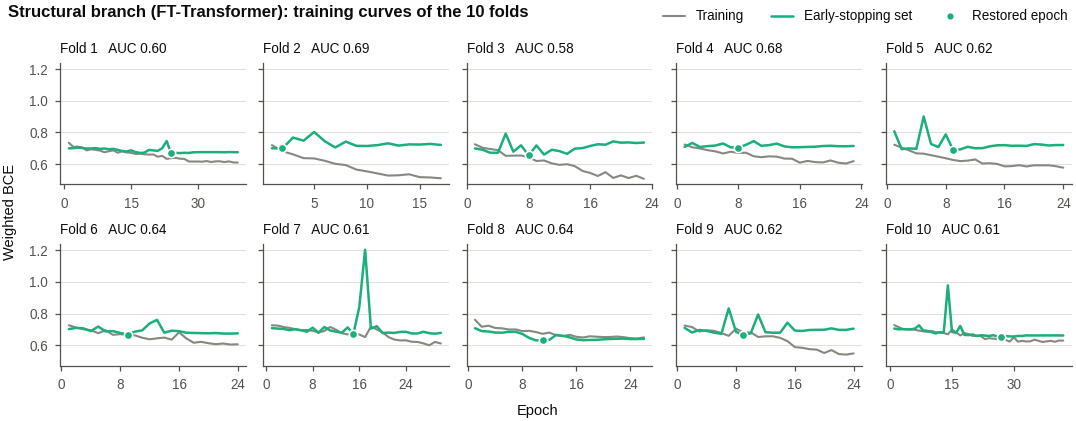

,fold,AUC,accuracy,knn_k,epochs
0,0,0.604805,0.611511,1,39
1,1,0.688070,0.618705,1,17
2,2,0.584921,0.532374,1,23
3,3,0.677311,0.615942,1,23
4,4,0.622689,0.594203,1,24
5,5,0.644328,0.623188,1,24
6,6,0.605882,0.557971,1,30
7,7,0.643067,0.601449,1,26
8,8,0.620798,0.586957,1,24
9,9,0.609034,0.594203,1,42


In [22]:
metrics_struct = summarize(RES_STRUCT, 'structural branch')
plot_histories(RES_STRUCT, C_MODEL['struct'], 'Structural branch (FT-Transformer): training curves of the 10 folds',
               name=f'history_struct_{GRAPH}')
metrics_struct

In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_training_struct = tracker.stop_task()
    tracker.start_task("Training functional model")

## 8. Functional branch (GATv2 only)

The functional-only model is the GAT on the subject graph followed by the head. It is the part of the model that **depends on the graph**: with `GRAPH = 'knn_strict'` it sees the `k = 1` graph (default), with `'complete'` all connections. Same loop as before, with the functional wrapper.

In [23]:
# Train the 10 folds (TRAIN = True) or load the pretrained checkpoints (TRAIN = False)
RES_FUNCT = get_results('funct')

fold  1  AUC 0.833  acc 0.719  epochs  24  (7.7s)
fold  2  AUC 0.773  acc 0.676  epochs  27  (8.8s)
fold  3  AUC 0.858  acc 0.784  epochs  18  (6.3s)
fold  4  AUC 0.847  acc 0.768  epochs  19  (4.2s)
fold  5  AUC 0.879  acc 0.790  epochs  20  (11.5s)
fold  6  AUC 0.856  acc 0.783  epochs  32  (10.7s)
fold  7  AUC 0.788  acc 0.696  epochs  48  (26.2s)
fold  8  AUC 0.848  acc 0.754  epochs  23  (7.2s)
fold  9  AUC 0.783  acc 0.616  epochs  19  (11.0s)
fold 10  AUC 0.790  acc 0.674  epochs  30  (9.6s)


functional branch (knn_strict): AUC 0.826 (+- 0.036) | accuracy 0.726 (+- 0.056)


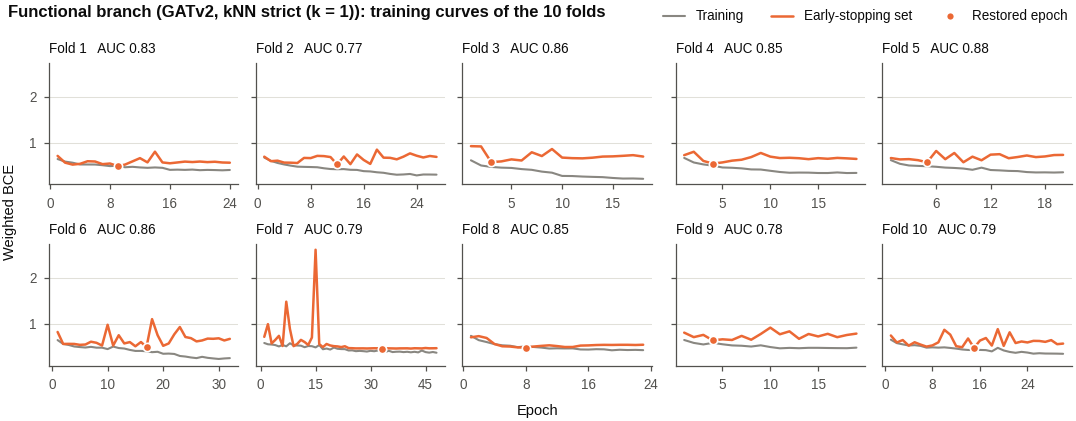

,fold,AUC,accuracy,knn_k,epochs
0,0,0.832643,0.719424,1,24
1,1,0.773405,0.676259,1,27
2,2,0.858326,0.784173,1,18
3,3,0.847479,0.768116,1,19
4,4,0.878782,0.789855,1,20
5,5,0.856092,0.782609,1,32
6,6,0.788025,0.695652,1,48
7,7,0.848319,0.753623,1,23
8,8,0.783403,0.615942,1,19
9,9,0.790126,0.673913,1,30


In [24]:
metrics_funct = summarize(RES_FUNCT, f'functional branch ({GRAPH})')
plot_histories(RES_FUNCT, C_MODEL['funct'], f'Functional branch (GATv2, {LABEL_GRAPH[GRAPH]}): training curves of the 10 folds',
               name=f'history_funct_{GRAPH}')
metrics_funct

In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_training_funct = tracker.stop_task()
    tracker.start_task("Training joint model")

## 9. Joint Fusion++

The full model: GAT + FT-Transformer + fusion head, **trained end to end** with a single loss, so the gradient reaches both encoders. Same loop, `kind = 'joint'`. The checkpoint of fold $k$ is `joint_fold{k}_seed0.pt`.

In [25]:
# Train the 10 folds (TRAIN = True) or load the pretrained checkpoints (TRAIN = False)
RES_JOINT = get_results('joint')

fold  1  AUC 0.829  acc 0.755  epochs  27  (12.4s)
fold  2  AUC 0.780  acc 0.655  epochs  19  (8.4s)
fold  3  AUC 0.875  acc 0.763  epochs  17  (7.7s)
fold  4  AUC 0.839  acc 0.710  epochs  20  (5.9s)
fold  5  AUC 0.869  acc 0.768  epochs  24  (19.7s)
fold  6  AUC 0.878  acc 0.790  epochs  48  (20.3s)
fold  7  AUC 0.794  acc 0.667  epochs  19  (17.3s)
fold  8  AUC 0.851  acc 0.761  epochs  22  (8.8s)
fold  9  AUC 0.793  acc 0.739  epochs  25  (21.5s)
fold 10  AUC 0.817  acc 0.696  epochs  24  (11.4s)


joint fusion++ (knn_strict): AUC 0.833 (+- 0.034) | accuracy 0.730 (+- 0.044)


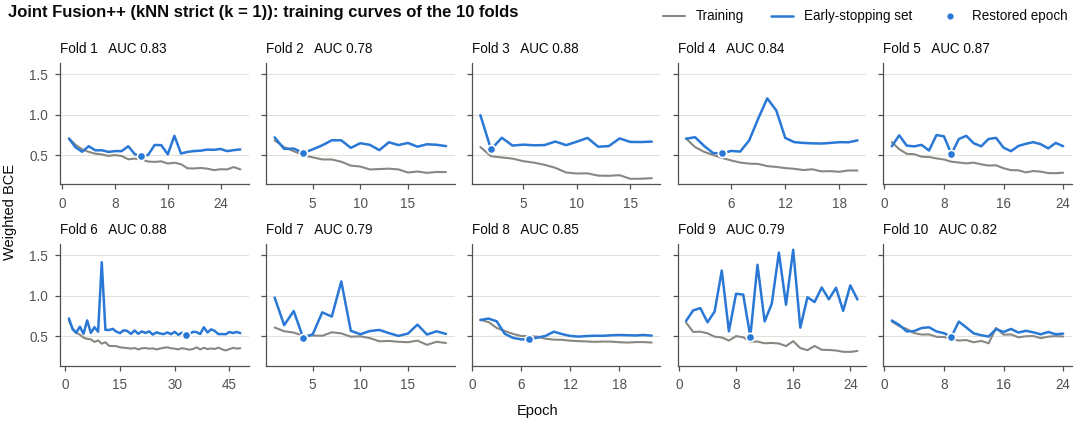

,fold,AUC,accuracy,knn_k,epochs
0,0,0.828915,0.755396,1,27
1,1,0.780240,0.654676,1,19
2,2,0.875311,0.762590,1,17
3,3,0.839286,0.710145,1,20
4,4,0.869118,0.768116,1,24
5,5,0.877521,0.789855,1,48
6,6,0.794118,0.666667,1,19
7,7,0.850840,0.760870,1,22
8,8,0.792857,0.739130,1,25
9,9,0.817227,0.695652,1,24


In [26]:
metrics_joint = summarize(RES_JOINT, f'joint fusion++ ({GRAPH})')
if GRAPH == 'knn_strict' and any(r['knn_k'] != KNN_K for r in RES_JOINT):
    print('note: the checkpoints were trained with k =', sorted({r['knn_k'] for r in RES_JOINT}), '(KNN_K =', KNN_K, ')')
plot_histories(RES_JOINT, C_MODEL['joint'], f'Joint Fusion++ ({LABEL_GRAPH[GRAPH]}): training curves of the 10 folds',
               name=f'history_joint_{GRAPH}')
metrics_joint

### 9.1 Mean ROC curves: structural, functional and joint

Each fold gives one ROC curve, interpolated on a common grid of false-positive rates; panel **a** shows the mean curve and ±1 standard deviation across the 10 folds, panel **b** the test AUC of every fold. The metrics are also saved to CSV (suffix `_trained` when the models were trained in this notebook).

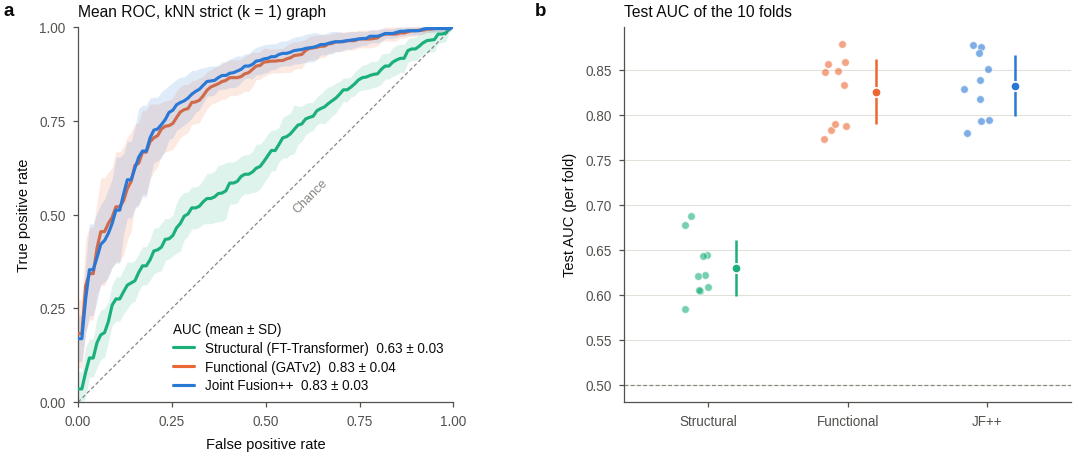

In [27]:
MODELS = (('struct', RES_STRUCT), ('funct', RES_FUNCT), ('joint', RES_JOINT))
fig, ax = plt.subplots(1, 2, figsize=(FIG_W2, 78 * MM), layout='constrained', gridspec_kw={'width_ratios': [1.15, 1]})
for z, (kind, res) in enumerate(MODELS):
    plot_mean_roc(ax[0], [r['tpr'] for r in res], [r['auc'] for r in res], C_MODEL[kind], LABEL_MODEL[kind], z=2 + 2 * z)
style_roc(ax[0])
ax[0].set_title(f'Mean ROC, {LABEL_GRAPH[GRAPH]} graph')
plot_fold_auc(ax[1], [(LABEL_MODEL_SHORT[kind], [r['auc'] for r in res], C_MODEL[kind]) for kind, res in MODELS])
ax[1].set_title('Test AUC of the 10 folds')
panel_label(ax[0], 'a'); panel_label(ax[1], 'b')
save_fig(fig, f'roc_models_{GRAPH}')

os.makedirs(OUT_DIR, exist_ok=True)
for name, df in (('structural', metrics_struct), ('functional', metrics_funct), ('joint', metrics_joint)):
    df.to_csv(os.path.join(OUT_DIR, f'jfpp_{GRAPH}_{name}_metrics_10kf.csv'), index=False)
pd.DataFrame({'fpr': INTERP_FPR, **{f'tpr_fold{r["fold"]}': r['tpr'] for r in RES_JOINT}}).to_csv(
    os.path.join(OUT_DIR, f'jfpp_{GRAPH}_joint_roc_10kf.csv'), index=False)

In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_training_joint = tracker.stop_task()
    tracker.start_task("Sparsification analysis")

## 10. The effect of sparsification

We have used the `k = 1` kNN-strict graph so far. What does sparsification actually do? We study it on **three levels**, always comparing with the complete graph:

1. **The graphs**: how many edges, which degrees, how many connected components remain for each `k` (10.1-10.3).
2. **What the network does with them**: the shape of the GAT attention (10.4) and the computational cost (10.6).
3. **What it costs in accuracy**: the 10-fold AUC of the kNN-strict model against the complete-graph model (10.5), and what happens when the graph rule is changed at inference time on already-trained weights (10.7).

Only the two versions asked for in this exercise are compared: **kNN strict** and **complete**. All the statistics of 10.1-10.3 use the raw (unscaled) connectivity of 300 random subjects and do not need any trained weight.

### 10.1 Size and shape of the graphs as a function of `k`

For each `k` we build the kNN graph of every subject and measure the number of undirected edges, the density (share of the 5253 connections kept), the degree of the nodes, the number of connected components and the mean $|r|$ of the kept connections (the kNN rule keeps the strongest ones, so it is higher than the mean of all connections).

A property worth checking for `k = 1`: every region picks exactly one neighbour, so the graph is a set of trees, each with exactly one pair of mutually-nearest regions. Hence **edges + connected components = 103** (up to ties).

In [28]:
SWEEP_KS_GRAPH = [1, 2, 3, 5, 7, 10, 15, 20]
rng = np.random.default_rng(0)
SUB = np.sort(rng.choice(len(D['y']), 300, replace=False))        # subjects used for the graph statistics
XF_SUB = D['X'][SUB, N_STRUCT:]
INC = np.zeros((N_FUNC, N_REGIONS), np.float32)
INC[np.arange(N_FUNC), IU] = 1; INC[np.arange(N_FUNC), JU] = 1


def graph_stats(masks, xf_raw):
    """masks [n, F] bool -> per-subject undirected edges, density, degrees, connected components, mean |r| kept."""
    deg = masks.astype(np.float32) @ INC                              # [n, R] degree of every region
    comps = np.empty(len(masks), int)
    for s, m in enumerate(masks):
        A = csr_matrix((np.ones(int(m.sum())), (IU[m], JU[m])), shape=(N_REGIONS, N_REGIONS))
        comps[s] = connected_components(A, directed=False)[0]
    return {'edges': masks.sum(1), 'density': masks.mean(1), 'deg': deg, 'comps': comps,
            'abs_r': (np.abs(xf_raw) * masks).sum(1) / masks.sum(1)}


MASKS_SUB = {k: knn_feature_mask(XF_SUB, k) for k in SWEEP_KS_GRAPH}
MASKS_SUB['complete'] = np.ones((len(SUB), N_FUNC), bool)
GSTAT = {k: graph_stats(m, XF_SUB) for k, m in MASKS_SUB.items()}

rows = []
for k, s in GSTAT.items():
    rows.append({'graph': 'complete' if k == 'complete' else f'kNN strict, k={k}',
                 'undirected edges': f'{s["edges"].mean():.0f} +- {s["edges"].std():.0f}',
                 '% of 5253': round(100 * s['density'].mean(), 2),
                 'mean degree': round(s['deg'].mean(), 1), 'min degree': int(s['deg'].min()),
                 'max degree (mean over subjects)': round(s['deg'].max(1).mean(), 1),
                 'connected components': round(s['comps'].mean(), 1),
                 'mean |r| of kept connections': round(s['abs_r'].mean(), 3)})
display(pd.DataFrame(rows).set_index('graph'))

s1 = GSTAT[1]
print('k = 1: edges + components == 103 in', int((s1['edges'] + s1['comps'] == N_REGIONS).sum()), 'of', len(SUB), 'subjects')

,undirected edges,% of 5253,mean degree,min degree,max degree (mean over subjects),connected components,mean |r| of kept connections
graph,,,,,,,
"kNN strict, k=1",80 +- 3,1.52,1.500000,1,4.600000,23.3,8.990
"kNN strict, k=2",151 +- 5,2.88,2.900000,2,7.400000,1.2,8.354
"kNN strict, k=3",221 +- 8,4.20,4.300000,3,10.000000,1.0,7.910
"kNN strict, k=5",355 +- 12,6.77,6.900000,5,14.800000,1.0,7.283
"kNN strict, k=7",487 +- 16,9.26,9.400000,7,19.299999,1.0,6.835
"kNN strict, k=10",679 +- 24,12.93,13.200000,10,25.200001,1.0,6.337
"kNN strict, k=15",990 +- 33,18.85,19.200001,15,34.299999,1.0,5.750
"kNN strict, k=20",1288 +- 43,24.51,25.000000,20,42.099998,1.0,5.324
complete,5253 +- 0,100.00,102.000000,102,102.000000,1.0,2.548


k = 1: edges + components == 103 in 300 of 300 subjects


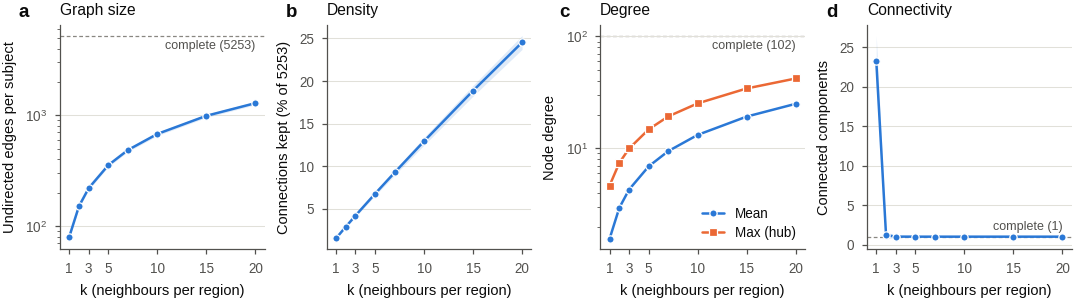

In [29]:
ks = np.array(SWEEP_KS_GRAPH)
c = C_GRAPH['knn_strict']

def line_sd(ax, x, m, s=None, color=c, marker='o', label=None):
    if s is not None:
        ax.fill_between(x, m - s, m + s, color=color, alpha=.15, lw=0)
    ax.plot(x, m, color=color, marker=marker, ms=3.5, mec='white', mew=0.6, label=label)

def ref_line(ax, y, text, va='bottom'):
    ax.axhline(y, color=MUTED, lw=0.6, ls=(0, (3, 2)), zorder=0)
    ax.annotate(text, (ks[-1], y), xytext=(0, 2 if va == 'bottom' else -2), textcoords='offset points',
                color=INK2, fontsize=6, ha='right', va=va)

fig, ax = plt.subplots(1, 4, figsize=(FIG_W2, 52 * MM), layout='constrained')

line_sd(ax[0], ks, np.array([GSTAT[k]['edges'].mean() for k in ks]), np.array([GSTAT[k]['edges'].std() for k in ks]))
ref_line(ax[0], N_FUNC, 'complete (5253)', va='top')
ax[0].set_yscale('log'); ax[0].set_ylabel('Undirected edges per subject'); ax[0].set_title('Graph size')

line_sd(ax[1], ks, np.array([100 * GSTAT[k]['density'].mean() for k in ks]),
        np.array([100 * GSTAT[k]['density'].std() for k in ks]))
ax[1].set_ylabel('Connections kept (% of 5253)'); ax[1].set_title('Density')

line_sd(ax[2], ks, np.array([GSTAT[k]['deg'].mean() for k in ks]), label='Mean')
line_sd(ax[2], ks, np.array([GSTAT[k]['deg'].max(1).mean() for k in ks]), color=C_MODEL['funct'], marker='s',
        label='Max (hub)')
ref_line(ax[2], N_REGIONS - 1, 'complete (102)', va='top')
ax[2].set_yscale('log'); ax[2].set_ylabel('Node degree'); ax[2].set_title('Degree'); ax[2].legend(loc='lower right')

line_sd(ax[3], ks, np.array([GSTAT[k]['comps'].mean() for k in ks]), np.array([GSTAT[k]['comps'].std() for k in ks]))
ref_line(ax[3], 1, 'complete (1)')
ax[3].set_ylabel('Connected components'); ax[3].set_title('Connectivity')

for a, lab in zip(ax, 'abcd'):
    a.set_xlabel('k (neighbours per region)'); a.set_xticks(ks[[0, 2, 3, 5, 6, 7]]); ygrid(a); panel_label(a, lab)
save_fig(fig, 'graph_size_vs_k')

### 10.2 One subject, complete graph versus kNN strict graphs

Top row: the connectivity matrix as the **node features** see it. For the kNN strict graph, the removed connections are zero, so the matrix becomes sparse (a few non-zero entries per row). Bottom row: the same graphs drawn on a circle, one point per region (red = positive correlation, blue = negative, same colour scale as the matrices; width proportional to $|r|$). The region order on the circle is the index order, not an anatomical one.

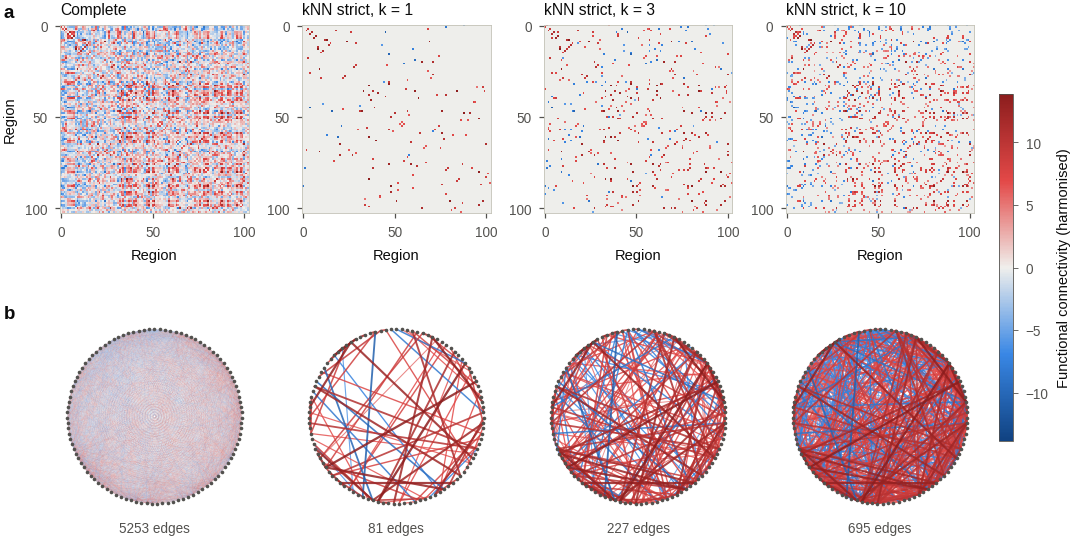

In [30]:
def draw_circular(ax, vec, mask, norm, lw_range=(0.15, 1.1), lw_full=0.1):
    """Graph of one subject on a circle (index order). Edges coloured with CMAP_DIV, width proportional to |r|
    (a fixed thin width when there are more than 1000 edges)."""
    th = np.linspace(0, 2 * np.pi, N_REGIONS, endpoint=False) + np.pi / 2
    xy = np.c_[np.cos(th), np.sin(th)]
    sel = np.flatnonzero(mask)
    sel = sel[np.argsort(np.abs(vec[sel]))]                 # strongest connections drawn on top
    segs = np.stack([xy[IU[sel]], xy[JU[sel]]], axis=1)
    w = np.abs(vec[sel])
    full = len(sel) > 1000
    lo, hi = lw_range
    widths = lw_full if full else lo + (hi - lo) * w / (w.max() or 1)
    ax.add_collection(LineCollection(segs, colors=CMAP_DIV(norm(vec[sel])), linewidths=widths,
                                     alpha=(0.2 if full else 0.85), capstyle='round'))
    ax.scatter(xy[:, 0], xy[:, 1], s=3, color=INK2, lw=0, zorder=3)
    ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08); ax.set_aspect('equal'); ax.axis('off')
    ax.text(0, -1.2, f'{len(sel)} edges', ha='center', va='top', fontsize=6.5, color=INK2)

SHOW_KS = [1, 3, 10]
i_show = 0                                             # index inside SUB
vec = XF_SUB[i_show]
variants = [('Complete', MASKS_SUB['complete'][i_show])] + [(f'kNN strict, k = {k}', MASKS_SUB[k][i_show]) for k in SHOW_KS]
lim = np.abs(vec).max()
norm = mpl.colors.Normalize(-lim, lim)
fig, axes = plt.subplots(2, len(variants), figsize=(FIG_W2, 100 * MM), layout='constrained')
for j, (name, m) in enumerate(variants):
    im = axes[0, j].imshow(vec_to_matrix(vec * m), cmap=CMAP_DIV, norm=norm, interpolation='nearest')
    axes[0, j].set_title(name)
    axes[0, j].set_xticks([0, 50, 100]); axes[0, j].set_yticks([0, 50, 100])
    axes[0, j].set_xlabel('Region')
    if j == 0:
        axes[0, j].set_ylabel('Region')
    for s in axes[0, j].spines.values():
        s.set_visible(True); s.set_linewidth(0.4); s.set_color(AXIS)
    draw_circular(axes[1, j], vec, m, norm)
panel_label(axes[0, 0], 'a', x=-0.3); panel_label(axes[1, 0], 'b', x=-0.3, y=1.0)
cb = fig.colorbar(im, ax=axes, shrink=0.6, aspect=25, pad=0.02)
cb.set_label('Functional connectivity (harmonised)'); cb.outline.set_linewidth(0.4); cb.ax.tick_params(width=0.4)
save_fig(fig, 'graph_example_subject')

### 10.3 Are the sparse graphs the same for every subject?

The kNN graph is computed **per subject** from its own connectivity, so it is not a fixed anatomical skeleton. Two questions:
- **Overlap**: for random pairs of subjects, what is the Jaccard index of their edge sets (1 = identical graphs)?
- **Coverage**: how many of the 5253 connections are an edge in *at least one* subject, and in at least 5 % of the subjects?

A low overlap with high coverage means that sparsification selects *different* strong connections in different people, so the model still sees the whole connectome across the dataset even though each single graph is very small.

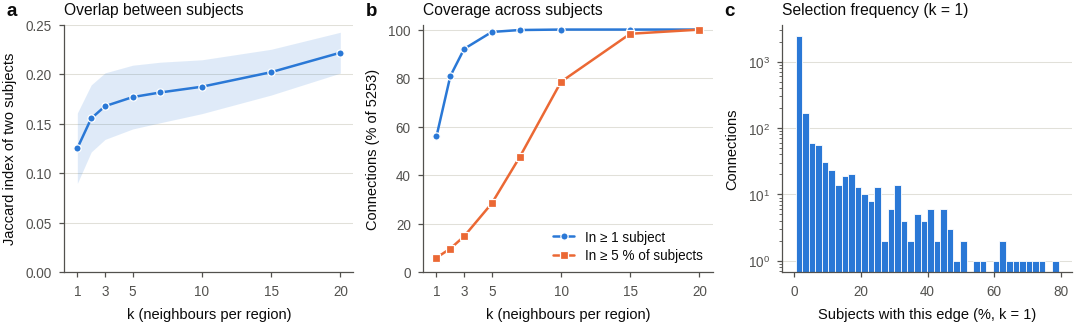

In [31]:
def pairwise_jaccard(masks, n_pairs=3000, seed=0):
    r = np.random.default_rng(seed)
    i, j = r.integers(0, len(masks), n_pairs), r.integers(0, len(masks), n_pairs)
    ok = i != j
    i, j = i[ok], j[ok]
    return (masks[i] & masks[j]).sum(1) / (masks[i] | masks[j]).sum(1)

jac = {k: pairwise_jaccard(MASKS_SUB[k]) for k in SWEEP_KS_GRAPH}
pres = {k: MASKS_SUB[k].mean(0) for k in SWEEP_KS_GRAPH}
ks = np.array(SWEEP_KS_GRAPH)
c = C_GRAPH['knn_strict']

fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 56 * MM), layout='constrained')
m, s = np.array([jac[k].mean() for k in ks]), np.array([jac[k].std() for k in ks])
ax[0].fill_between(ks, m - s, m + s, color=c, alpha=.15, lw=0)
ax[0].plot(ks, m, color=c, marker='o', ms=3.5, mec='white', mew=0.6)
ax[0].set_xlabel('k (neighbours per region)'); ax[0].set_ylabel('Jaccard index of two subjects')
ax[0].set_title('Overlap between subjects'); ax[0].set_ylim(0, None)

ax[1].plot(ks, [100 * (pres[k] > 0).mean() for k in ks], color=c, marker='o', ms=3.5, mec='white', mew=0.6,
           label='In ≥ 1 subject')
ax[1].plot(ks, [100 * (pres[k] >= 0.05).mean() for k in ks], color=C_MODEL['funct'], marker='s', ms=3.5, mec='white',
           mew=0.6, label='In ≥ 5 % of subjects')
ax[1].set_xlabel('k (neighbours per region)'); ax[1].set_ylabel('Connections (% of 5253)')
ax[1].set_title('Coverage across subjects'); ax[1].set_ylim(0, 102); ax[1].legend(loc='lower right')

ax[2].hist(100 * pres[1][pres[1] > 0], bins=40, color=c, edgecolor='white', linewidth=0.4)
ax[2].set_yscale('log'); ax[2].set_xlabel('Subjects with this edge (%, k = 1)')
ax[2].set_ylabel('Connections'); ax[2].set_title('Selection frequency (k = 1)')
for a, lab in zip(ax, 'abc'):
    ygrid(a); panel_label(a, lab)
for a in ax[:2]:
    a.set_xticks(ks[[0, 2, 3, 5, 6, 7]])
save_fig(fig, 'graph_overlap_coverage')

### 10.4 AUC: kNN strict against complete

This comparison always uses the **provided** hyperparameters and weights of both runs (`./params/<run>` and `./weights/<run>`), whatever `TRAIN` is. We first check that the hyperparameters stored in every checkpoint are the ones in its params folder.

Both models were tuned with the same nested Optuna protocol on the same ten folds, so the AUCs are **paired by fold**. We show the per-fold AUC, the paired difference and a paired Wilcoxon test. With only ten folds the test has little power: the mean difference and its spread across folds are as informative as the p-value.

complete    weights: ./weights/jfpp_complete_sgd_l1 | params: ./params/jfpp_complete_sgd_l1 | hyperparameters match in 10/10 folds
knn_strict  weights: ./weights/jfpp_knn_strict_sgd_l1 | params: ./params/jfpp_knn_strict_sgd_l1 | hyperparameters match in 10/10 folds
complete    AUC 0.689 (+- 0.038) | accuracy 0.633 (+- 0.034)
knn_strict  AUC 0.835 (+- 0.025) | accuracy 0.741 (+- 0.026)
AUC difference (strict - complete): +0.146 (+- 0.034); strict better in 10/10 folds
paired Wilcoxon (two-sided): p = 0.002


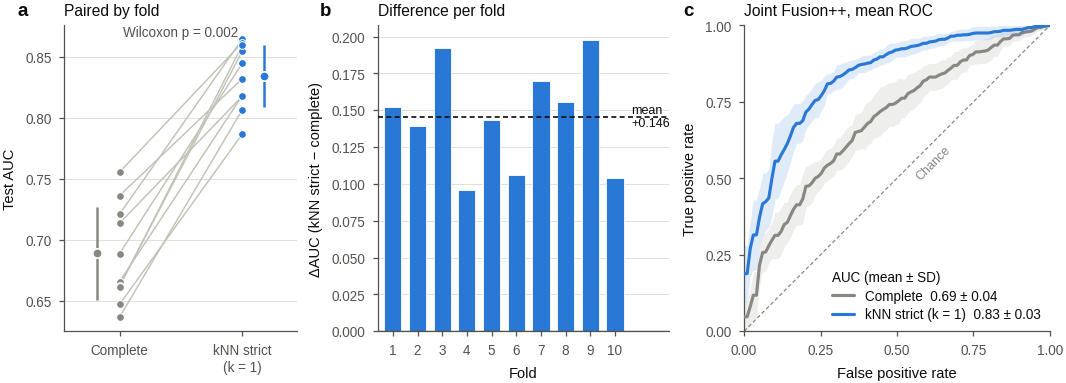

In [32]:
CMP = ('complete', 'knn_strict')
JOINT = {g: load_results(g, 'joint', RUN_DIRS[g]) for g in CMP}       # pretrained weights of both runs
PARAMS_CMP = {g: load_params(PARAM_DIRS[g]) for g in CMP}            # their best Optuna parameters

def same_kwargs(stored, ref):
    return all(np.isclose(stored[a], b) if isinstance(b, float) else stored[a] == b for a, b in ref.items())

for g in CMP:
    if PARAMS_CMP[g] is None:
        print(f'{g:11s} no params in {PARAM_DIRS[g]}')
        continue
    ok = [same_kwargs({**r['params'], **r['train_kwargs']}, {**mk, **tk})
          for r, (mk, tk) in zip(JOINT[g], map(params_to_kwargs, PARAMS_CMP[g]))]
    print(f'{g:11s} weights: {RUN_DIRS[g]} | params: {PARAM_DIRS[g]} | hyperparameters match in {sum(ok)}/{len(ok)} folds')

auc_g = {g: np.array([r['auc'] for r in JOINT[g]]) for g in CMP}
acc_g = {g: np.array([r['acc'] for r in JOINT[g]]) for g in CMP}
diff = auc_g['knn_strict'] - auc_g['complete']

for g in CMP:
    print(f'{g:11s} AUC {auc_g[g].mean():.3f} (+- {auc_g[g].std():.3f}) | accuracy {acc_g[g].mean():.3f} (+- {acc_g[g].std():.3f})')
print(f'AUC difference (strict - complete): {diff.mean():+.3f} (+- {diff.std():.3f}); strict better in {(diff > 0).sum()}/{len(diff)} folds')
p_w = stats.wilcoxon(auc_g['knn_strict'], auc_g['complete']).pvalue if np.any(diff != 0) else np.nan
print(f'paired Wilcoxon (two-sided): p = {p_w:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 66 * MM), layout='constrained', gridspec_kw={'width_ratios': [0.8, 1, 1.2]})

# a: paired AUC per fold
for k in range(N_OUTER):
    ax[0].plot([0, 1], [auc_g['complete'][k], auc_g['knn_strict'][k]], color=AXIS, lw=0.7, zorder=1)
for x, g in enumerate(CMP):
    ax[0].scatter(np.full(N_OUTER, x), auc_g[g], s=14, color=C_GRAPH[g], edgecolor='white', linewidth=0.5, zorder=3)
    ax[0].errorbar(x + (0.18 if x else -0.18), auc_g[g].mean(), auc_g[g].std(), fmt='o', color=C_GRAPH[g], ms=4.5,
                   mec='white', mew=0.8, elinewidth=1.2, capsize=0, zorder=4)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['Complete', f'kNN strict\n(k = {KNN_K})']); ax[0].set_xlim(-0.45, 1.45)
ax[0].set_ylabel('Test AUC'); ax[0].set_title('Paired by fold'); ygrid(ax[0])
ax[0].text(0.5, 1.0, 'Wilcoxon p < 0.001' if p_w < 1e-3 else f'Wilcoxon p = {p_w:.3f}', transform=ax[0].transAxes, ha='center', va='top', fontsize=6.5,
           color=INK2)

# b: paired difference per fold
folds = np.arange(1, N_OUTER + 1)
ax[1].bar(folds, diff, width=0.7, color=C_GRAPH['knn_strict'], edgecolor='white', linewidth=0.4, zorder=2)
ax[1].axhline(0, color=INK2, lw=0.6, zorder=3)
ax[1].axhline(diff.mean(), color=INK, lw=0.8, ls=(0, (3, 2)), zorder=3)
ax[1].set_xlim(0.4, N_OUTER + 2.2)
ax[1].annotate(f'mean\n{diff.mean():+.3f}', (N_OUTER + 0.5, diff.mean()), xytext=(2, 0), textcoords='offset points',
               ha='left', va='center', fontsize=6, color=INK)
ax[1].set_xticks(folds); ax[1].set_xlabel('Fold'); ax[1].set_ylabel('ΔAUC (kNN strict − complete)')
ax[1].set_title('Difference per fold'); ygrid(ax[1])

# c: mean ROC
for z, g in enumerate(CMP):
    plot_mean_roc(ax[2], [r['tpr'] for r in JOINT[g]], auc_g[g], C_GRAPH[g], LABEL_GRAPH[g], z=2 + 2 * z)
style_roc(ax[2]); ax[2].set_title('Joint Fusion++, mean ROC')

for a, lab in zip(ax, 'abc'):
    panel_label(a, lab)
save_fig(fig, 'auc_knn_strict_vs_complete')

In [ ]:
# ENERGY MONITORING
if energy_monitoring:
    emissions_sparsification = tracker.stop_task()
    tracker.start_task("Explanations (SHAP and attention)")

## 11. Explaining Joint Fusion++: conditional SHAP and attention

We now open the pretrained / trained **joint** model (fold by fold) with two complementary read-outs, both computed on the test subjects of the fold the model never saw:

* **SHAP** (`shap.GradientExplainer`, i.e. expected gradients) explains the *logit* of the whole network: how much every input feature (221 structural values, 5253 connections) pushes the prediction of a subject towards ASD or TD. It uses 100 stratified training subjects as background and 200 samples per explained subject (the same settings of the paper).
* **Attention** is a by-product of the forward pass: the weights of the first GATv2 layer (one per edge, averaged over the 8 heads) for the connections, and the `[CLS] → feature` weights of the first Transformer block for the structural features. It is *not* a statement about the output of the network, only about how the model mixes its inputs, so we treat it as a candidate explanation and compare it with SHAP.

**Why a "conditional" SHAP?** With the kNN-strict graph (`k = 1`) a connection exists only in the graph of the subjects for which it is among the strongest one of a region; for the others it is absent (edge removed *and* value set to 0), so its SHAP value is trivially 0. A plain mean over all subjects would therefore mostly measure *how often* a connection is present. The **presence-conditional** SHAP averages $|\mathrm{SHAP}_{ij}|$ **only over the subjects whose graph contains connection $j$**:

$$ c_j = \frac{\sum_i p_{ij}\,|\mathrm{SHAP}_{ij}|}{\sum_i p_{ij}}, \qquad p_{ij}\in\{0,1\} \text{ (connection } j \text{ present in subject } i\text{)} $$

The same correction is applied to attention (mean attention divided by presence). For the complete graph every connection is always present, so conditional and plain means coincide. In the paper, connections present in fewer than 5 % of the test subjects in some fold are not eligible for the rankings.

The SHAP computation is the heavy part of the notebook (a few minutes per fold on a GPU, longer on CPU). Set `EXPLAIN_FOLDS` to a subset of folds for a quick look; results are cached in `./results/explain/<graph>/` and reused.

In [ ]:
import shap
SHAP_NSAMPLES, SHAP_BACKGROUND = 200, 100
EXPLAIN_FOLDS = list(range(N_OUTER))          # e.g. [0, 1] for a quick look
MIN_PRESENCE, TOP_FRAC = 0.05, 0.01          # eligibility threshold of a connection, "top 1 %" = crucial
EXPLAIN_DIR = os.path.join(OUT_DIR, 'explain', GRAPH)
os.makedirs(EXPLAIN_DIR, exist_ok=True)
# Joint checkpoints used for the explanations: the ones trained above (TRAIN = True) or the pretrained ones
EXPL_WEIGHTS = TRAIN_WEIGHTS if TRAIN else RUN_DIRS[GRAPH]
print('explaining the checkpoints in', EXPL_WEIGHTS, '| folds', EXPLAIN_FOLDS, '| device', DEVICE)

class _ShapAdapter(nn.Module):
    """Presents f(x_struct, x_funct) -> logit to shap, with both inputs explained."""
    def __init__(self, net):
        super().__init__(); self.net = net
    def forward(self, xs, xf):
        return self.net(xs, xf)

def shap_explain(net, background, inputs, nsamples=SHAP_NSAMPLES, batch_size=50, seed=0):
    """GradientExplainer (expected gradients) of the logit. background / inputs: [x_struct, x_funct] arrays.
    Returns [shap_struct [n, 221], shap_funct [n, 5253]]. On CUDA out-of-memory the batch is halved."""
    t = lambda a: torch.as_tensor(np.asarray(a, np.float32), device=DEVICE)
    model = _ShapAdapter(net).eval()
    while True:
        expl = shap.GradientExplainer(model, [t(b) for b in background], batch_size=batch_size)
        try:
            sv = expl.shap_values([t(x) for x in inputs], nsamples=nsamples, rseed=seed)
            break
        except torch.cuda.OutOfMemoryError:
            if batch_size == 1: raise
        torch.cuda.empty_cache(); batch_size //= 2
    return [np.asarray(s, dtype=np.float32).reshape(len(inputs[0]), -1) for s in sv]

def conditional_shap(S, present, y):
    """Presence-conditional SHAP of one fold. S [n, F] SHAP of the test subjects, present [n, F] bool (None = all
    present), y [n] (1 = ASD). Returns presence p_j, conditional c_j = mean |SHAP| over the subjects that have j
    (NaN if nobody), mean_abs (all subjects), and the signed mean of the ASD / TD subjects that have j."""
    S = np.asarray(S, np.float64); y = np.asarray(y).astype(int)
    P = np.ones(S.shape, bool) if present is None else np.asarray(present, bool)
    def cmean(V, M):
        c = M.sum(0)
        return np.divide(np.where(M, V, 0.0).sum(0), c, out=np.full(V.shape[1], np.nan), where=c > 0)
    A = np.abs(S)
    out = {'presence': P.mean(0), 'conditional': cmean(A, P), 'mean_abs': A.mean(0)}
    out['conditional'][P.all(0)] = out['mean_abs'][P.all(0)]
    out['ASD'], out['TD'] = cmean(S[y == 1], P[y == 1]), cmean(S[y == 0], P[y == 0])
    return out

@torch.no_grad()
def attention_readouts(net, Xs, Xf, y, keep=None, batch_size=32, n_func=N_FUNC):
    """First-layer GATv2 attention (heads averaged) of the joint model on a set of subjects, mapped onto the 5253
    connections (the two directions are averaged; absent connection = 0):
      mean        : mean over the subjects              presence    : share of the subjects whose graph has it
      conditional : mean / presence (mean over the subjects that have it)
      contrast    : mean over ASD - mean over TD
      morph       : mean [CLS] -> feature attention of the first Transformer block (221 values)"""
    net.eval(); y = np.asarray(y).astype(int)
    S = {c: torch.zeros(n_func, dtype=torch.float64, device=DEVICE) for c in (0, 1)}
    P = torch.zeros(n_func, dtype=torch.float64, device=DEVICE)
    M = torch.zeros(N_STRUCT, dtype=torch.float64, device=DEVICE)
    for i in range(0, len(Xs), batch_size):
        xs = torch.as_tensor(np.asarray(Xs[i:i + batch_size], np.float32), device=DEVICE)
        xf = torch.as_tensor(np.asarray(Xf[i:i + batch_size], np.float32), device=DEVICE)
        kw = {} if keep is None else {'keep': torch.as_tensor(np.asarray(keep[i:i + batch_size], bool), device=DEVICE)}
        _, a = net(xs, xf, return_attention=True, **kw)
        B = xs.shape[0]
        alpha, ef, es = a['alpha'].double(), a['edge_feat'], a['edge_subject']
        f_att = torch.zeros(B, n_func, dtype=torch.float64, device=DEVICE).index_put_((es, ef), alpha, accumulate=True) / 2
        cnt = torch.zeros(B, n_func, dtype=torch.float64, device=DEVICE).index_put_((es, ef), torch.ones_like(alpha), accumulate=True)
        P += (cnt > 0).double().sum(0)
        yb = torch.as_tensor(y[i:i + batch_size], device=DEVICE)
        for c in (0, 1):
            S[c] += f_att[yb == c].sum(0)
        M += a['morph'].double().sum(0)
    n0, n1 = int((y == 0).sum()), int((y == 1).sum()); n = n0 + n1
    mean = ((S[0] + S[1]) / n).cpu().numpy(); pres = (P / n).cpu().numpy()
    return {'mean': mean, 'presence': pres,
            'conditional': np.divide(mean, pres, out=np.zeros_like(mean), where=pres > 0),
            'contrast': (S[1] / max(n1, 1) - S[0] / max(n0, 1)).cpu().numpy(),
            'morph': (M / n).cpu().numpy()}

In [ ]:
def explain_fold(k):
    """SHAP + attention of the joint model of fold k on its test subjects (cached in EXPLAIN_DIR/fold{k}.npz)."""
    path = os.path.join(EXPLAIN_DIR, f'fold{k}.npz')
    if os.path.exists(path):
        return dict(np.load(path))
    tr, te = OUTER[k]
    net, ck, sc = load_ckpt(ckpt_path(EXPL_WEIGHTS, 'joint', k), G['strict'])
    bg = shap_background_idx(D['y'], tr, k, n=SHAP_BACKGROUND)          # training subjects only
    Xs_bg, Xf_bg = scaled(sc, D['X'], bg)
    Xs_te, Xf_te = scaled(sc, D['X'], te)
    y_te = D['y'][te].astype(int)
    keep_te = None if ck['knn_k'] is None else net.keep_from(torch.as_tensor(Xf_te, device=DEVICE)).cpu().numpy()
    t0 = time.time()
    s_struct, s_funct = shap_explain(net, [Xs_bg, Xf_bg], [Xs_te, Xf_te], seed=k)
    t_shap = time.time() - t0
    cs = conditional_shap(s_funct, keep_te, y_te)
    att = attention_readouts(net, Xs_te, Xf_te, y_te, keep_te)
    out = {'idx': te, 'shap_seconds': t_shap,
           'shap_f_cond': cs['conditional'], 'shap_f_meanabs': cs['mean_abs'], 'shap_f_ASD': cs['ASD'], 'shap_f_TD': cs['TD'],
           'presence': cs['presence'], 'shap_s_abs': np.abs(s_struct).mean(0),
           'shap_s_ASD': s_struct[y_te == 1].mean(0), 'shap_s_TD': s_struct[y_te == 0].mean(0),
           'att_f_mean': att['mean'], 'att_f_cond': att['conditional'], 'att_f_contrast': att['contrast'],
           'att_s': att['morph']}
    np.savez_compressed(path, **out)
    print(f'fold {k + 1:2d}: SHAP {t_shap:6.1f} s | presence of the connections: {100 * (out["presence"] > 0).mean():.0f} % in >= 1 subject')
    del net
    return out

EXPL = {k: explain_fold(k) for k in EXPLAIN_FOLDS}

### 11.1 Aggregating and saving

Each read-out gives one vector per fold. We stack them in the same tables used elsewhere in the project (one column per fold; `NaN` = a connection never present in that fold) and save them in `./results/explain/<graph>/`:

| File | Content |
|---|---|
| `shap_value_joint_functional_conditional_10kf.csv` | presence-conditional mean \|SHAP\| of the 5253 connections |
| `shap_value_jfpp_joint_morphological_10kf.csv` | mean \|SHAP\| of the 221 structural features |
| `attention_value_joint_functional_conditional_10kf.csv` | conditional first-layer GAT attention of the connections |
| `attention_value_joint_morphological_10kf.csv` | `[CLS]` attention of the 221 structural features |
| `knn_presence_functional_10kf.csv` | share of the test subjects whose graph contains the connection |
| `shap_signed_{ASD,TD}_*`, `attention_ASDminusTD_*` | signed SHAP of each class and attention contrast |

In [ ]:
def stack(key):
    return pd.DataFrame(np.vstack([EXPL[k][key] for k in EXPLAIN_FOLDS]).T, columns=EXPLAIN_FOLDS)

TABLES = {
    'shap_value_joint_functional_conditional_10kf.csv': 'shap_f_cond',
    'shap_value_jfpp_joint_morphological_10kf.csv': 'shap_s_abs',
    'shap_signed_ASD_conditional_functional_10kf.csv': 'shap_f_ASD',
    'shap_signed_TD_conditional_functional_10kf.csv': 'shap_f_TD',
    'shap_signed_ASD_jfpp_joint_morphological_10kf.csv': 'shap_s_ASD',
    'shap_signed_TD_jfpp_joint_morphological_10kf.csv': 'shap_s_TD',
    'attention_value_joint_functional_conditional_10kf.csv': 'att_f_cond',
    'attention_value_joint_functional_10kf.csv': 'att_f_mean',
    'attention_value_joint_morphological_10kf.csv': 'att_s',
    'attention_ASDminusTD_joint_functional_10kf.csv': 'att_f_contrast',
    'knn_presence_functional_10kf.csv': 'presence',
}
for fn, key in TABLES.items():
    stack(key).to_csv(os.path.join(EXPLAIN_DIR, fn))
print('saved', len(TABLES), 'tables in', EXPLAIN_DIR)

## 12. What do the two explanations say?

### 12.1 Functional connections: ROI × ROI importance matrices

The 5253 values of each explanation (mean over the folds) are laid out as a symmetric $102 \times 102$ matrix whose regions are grouped by the **Yeo 7 networks** (+ subcortical), using `data/ho_to_yeo_mapping.csv` (Harvard-Oxford → Yeo). Colour scale clipped at the 99th percentile. **a** conditional SHAP (blue), **b** conditional attention (red).

In [ ]:
def importance(name):
    """[n_features, n_folds] |values| of a saved table (NaN = feature absent in that fold)."""
    return pd.read_csv(os.path.join(EXPLAIN_DIR, name), index_col=0).abs().to_numpy(float)

FF = pd.read_csv(os.path.join(DATA_IN, 'functional_features.csv'))
YEO = pd.read_csv(os.path.join(DATA_IN, 'ho_to_yeo_mapping.csv')).sort_values(['yeo_roi', 'ho_roi'])
CODES = YEO.ho_roi.to_numpy()
NET_LABEL = YEO.yeo_label.str.replace('_Areas', '').str.replace('_Network', '').str.replace('_', ' ').to_numpy()
NET_ID = YEO.yeo_roi.to_numpy()

def functional_matrix(vec):
    idx = {c: i for i, c in enumerate(CODES)}
    M = np.full((len(CODES), len(CODES)), np.nan)
    for v, a, b in zip(vec, FF['ROI 1'], FF['ROI 2']):
        if a in idx and b in idx:
            M[idx[a], idx[b]] = M[idx[b], idx[a]] = v
    return M

def draw_matrix(ax, M, cmap, label):
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=np.nanpercentile(M, 99), interpolation='nearest')
    edges = np.flatnonzero(np.diff(NET_ID)) + 1
    for e in edges:
        ax.axhline(e - .5, color=INK, lw=.3); ax.axvline(e - .5, color=INK, lw=.3)
    b = np.r_[0, edges, len(NET_ID)]; mid = (b[:-1] + b[1:]) / 2 - .5
    ax.set_xticks(mid, [NET_LABEL[int(i)] for i in b[:-1]], rotation=90); ax.set_yticks(mid, [NET_LABEL[int(i)] for i in b[:-1]])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(True)
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label(label, fontsize=6); cb.ax.tick_params(labelsize=5)

SHAP_F = np.nanmean(importance('shap_value_joint_functional_conditional_10kf.csv'), axis=1)
ATT_F = np.nanmean(importance('attention_value_joint_functional_conditional_10kf.csv'), axis=1)
fig, ax = plt.subplots(1, 2, figsize=(FIG_W2, 82 * MM), layout='constrained')
draw_matrix(ax[0], functional_matrix(SHAP_F), 'Blues', 'conditional mean |SHAP|')
draw_matrix(ax[1], functional_matrix(ATT_F), 'Reds', 'conditional attention')
ax[0].set_title('SHAP'); ax[1].set_title('Attention')
panel_label(ax[0], 'a', x=-0.3); panel_label(ax[1], 'b', x=-0.3)
save_fig(fig, f'explain_matrices_{GRAPH}')

### 12.2 Structural features: top 20

Mean over the folds of the SHAP and of the `[CLS]` attention of the 221 FreeSurfer features. Attention is bounded and spread over many features (it sums to 1 over the 221 tokens), SHAP is in logit units, so only the *ordering* is comparable.

In [ ]:
SHAP_S = np.nanmean(importance('shap_value_jfpp_joint_morphological_10kf.csv'), axis=1)
ATT_S = np.nanmean(importance('attention_value_joint_morphological_10kf.csv'), axis=1)
names = [n.replace('_', ' ') for n in D['struct_names']]
fig, ax = plt.subplots(1, 2, figsize=(FIG_W2, 85 * MM), layout='constrained')
for a, v, col, xl, lab in ((ax[0], SHAP_S, C_MODEL['joint'], 'mean |SHAP|', 'a'), (ax[1], ATT_S, C_MODEL['funct'], 'mean [CLS] attention', 'b')):
    keep = np.argsort(v)[-20:]
    a.barh(range(20), v[keep], color=col, height=.7)
    a.set_yticks(range(20), [names[i] for i in keep]); a.tick_params(axis='y', labelsize=5.5)
    a.set_xlabel(xl); panel_label(a, lab, x=-0.55)
ax[0].set_title('SHAP'); ax[1].set_title('Attention')
save_fig(fig, f'explain_structural_{GRAPH}')

### 12.3 Do SHAP and attention agree?

Agreement between the two rankings, per fold and on the fold-mean, over the **eligible** connections (present in ≥ 5 % of the test subjects in every fold) and the 221 structural features:

* **Spearman** correlation of the whole ranking;
* **Jaccard** overlap of the top 1 % (connections) / top 10 (structural), with the value expected by chance;
* the table of the 10 most important connections for each method (mean normalised rank over the folds).

In [ ]:
from scipy.stats import spearmanr, rankdata
PRES = importance('knn_presence_functional_10kf.csv')
ELIG = (PRES >= MIN_PRESENCE).all(1)                      # eligible connections
SH, AT = importance('shap_value_joint_functional_conditional_10kf.csv'), importance('attention_value_joint_functional_conditional_10kf.csv')

def topk(v, k):
    return set(np.argsort(-v)[:k])
def jaccard(a, b, k):
    A, B = topk(a, k), topk(b, k)
    return len(A & B) / len(A | B)

rows = []
for j, k in enumerate(EXPLAIN_FOLDS):
    a, b = SH[ELIG, j], AT[ELIG, j]
    kk = max(1, int(round(TOP_FRAC * ELIG.sum())))
    rows.append({'fold': k, 'Spearman (connections)': spearmanr(a, b)[0], f'Jaccard top {kk} (connections)': jaccard(a, b, kk),
                 'Spearman (structural)': spearmanr(importance('shap_value_jfpp_joint_morphological_10kf.csv')[:, j],
                                                    importance('attention_value_joint_morphological_10kf.csv')[:, j])[0]})
agree = pd.DataFrame(rows).set_index('fold')
display(agree.round(3))
n_e = int(ELIG.sum()); kk = max(1, int(round(TOP_FRAC * n_e)))
print(f'eligible connections: {n_e}/{N_FUNC} | top {kk} | Jaccard expected by chance: {kk / (2 * n_e - kk):.4f}')
print('fold-mean ranking: Spearman = %.3f (connections), %.3f (structural)' % (
    spearmanr(SHAP_F[ELIG], ATT_F[ELIG])[0], spearmanr(SHAP_S, ATT_S)[0]))

def mean_rank(M):
    M = np.array(M, float); M[np.isnan(M) | ~ELIG[:, None]] = -np.inf
    return np.mean([rankdata(M[:, j]) / M.shape[0] for j in range(M.shape[1])], axis=0)
R_SH, R_AT = mean_rank(SH), mean_rank(AT)
def top_table(R, n=10):
    o = np.argsort(-R)[:n]
    return pd.DataFrame({'region 1': FF['r1'].to_numpy()[o], 'region 2': FF['r2'].to_numpy()[o], 'mean rank': R[o]})
display(pd.concat({'SHAP': top_table(R_SH), 'Attention': top_table(R_AT)}, axis=1).round(3))

## 13. Summary of the explanations

* **Conditional SHAP** and **attention** are computed for every fold on test subjects only, and saved as CSV tables.
* The matrices in Section 12.1 show *where* in the connectome (Yeo networks) each method concentrates its importance; Section 12.3 quantifies whether the two methods rank the same connections / features as important. Low agreement does not mean one of them is wrong: SHAP measures the effect of a feature on the output, attention measures how the model weights neighbours inside the first layer (Jain & Wallace, 2019).
* The comparison with the original Joint Fusion (MLP encoders, SHAP only) is in `Comparison.ipynb`.

### Energy report

Last ENERGY MONITORING cell: stops the last task and the global tracker, then shows the energy (kWh) and the emissions (g CO$_2$e) of each task and the **total of the whole notebook** (`NOTEBOOK_ENERGY`). It is safe to re-run: if the last task was already stopped, the cell only prints a message and stops the tracker.

In [ ]:
# ENERGY MONITORING: stop the tracker and report the kWh and the CO2e of the whole notebook
if energy_monitoring:
    try:
        emissions_expl = tracker.stop_task()        # last task: explanations (SHAP and attention)
    except Exception as e:                          # e.g. the task was already stopped (cell run twice)
        print('no active task to stop:', e)
    tracker.stop()                                  # stops the global tracker -> whole notebook
    tot = tracker.final_emissions_data              # EmissionsData of the whole run (kWh, kg CO2e)

    TASKS = [('Model definition', 'emissions_model_def'), ('Hyperparameter optimization', 'emissions_opt'),
             ('Training structural model', 'emissions_training_struct'), ('Training functional model', 'emissions_training_funct'),
             ('Training joint model', 'emissions_training_joint'), ('Sparsification analysis', 'emissions_sparsification'),
             ('Explanations (SHAP and attention)', 'emissions_expl')]
    rows = []
    for name, var in TASKS:
        d = globals().get(var)
        if d is not None:                           # a task is missing if its cell was not run
            rows.append(dict(task=name, duration_s=d.duration, kWh=d.energy_consumed, kWh_cpu=d.cpu_energy,
                             kWh_gpu=d.gpu_energy, kWh_ram=d.ram_energy, gCO2e=d.emissions * 1000))
    rows.append(dict(task='NOTEBOOK TOTAL', duration_s=tot.duration, kWh=tot.energy_consumed, kWh_cpu=tot.cpu_energy,
                     kWh_gpu=tot.gpu_energy, kWh_ram=tot.ram_energy, gCO2e=tot.emissions * 1000))
    NOTEBOOK_ENERGY = pd.DataFrame(rows).set_index('task')
    display(NOTEBOOK_ENERGY)
    print(f'Notebook: {tot.energy_consumed:.5f} kWh | {tot.emissions * 1000:.3f} g CO2e '
          f'(carbon intensity of the region used by codecarbon: {tot.emissions * 1000 / max(tot.energy_consumed, 1e-12):.0f} gCO2e/kWh)')
else:
    print('energy_monitoring = False: nothing to stop')

## 14. Computational cost per fold (MFLOPs, kWh, CO$_2$e)

This section rebuilds the table `./data/comparison/computational_cost_per_fold.csv` used in `Comparison.ipynb`, one row per outer fold. It is independent of the global tracker above (which must be **already stopped**: run it after the Energy report), because every phase of every fold gets its own short `codecarbon` tracker.

| Column group | How it is measured |
|---|---|
| `params` | trainable parameters of the joint network |
| `mflops_per_subject` | **hardware-independent** forward cost per subject, in MFLOPs ($1\,\text{FLOP} = $ one add or one multiply, so a multiply-accumulate counts 2). `torch.utils.flop_counter.FlopCounterMode` counts every matrix product (linear layers, attention, GATv2 projections); the part it cannot see, the per-edge gather / softmax / aggregation of GATv2, is added analytically (`7·H·C + 3·H` per directed edge and per layer). A training step costs roughly 3× the forward. |
| `train_act_MB_per_subject` | memory of the tensors saved for the backward pass (without the weights), per subject |
| `directed_edges` | mean number of directed edges per test subject (`2 × 5253` for the complete graph) |
| `n_trials`, `best_inner_auc` | from the stored Optuna `trials.csv` of the fold |
| `epochs`, `best_epoch`, `s_per_epoch`, `train_s`, `peak_train_mem_MB` | training of the fold (peak GPU memory is `NaN` without a GPU) |
| `reps`, `infer_loop_s`, `ms_per_subject`, `mJ_per_subject`, `mgCO2_per_subject` | inference: the test fold is predicted again and again for a time budget (30 s in the stored table); energy and CO$_2$e are divided by `reps × n_test` |
| `opt_*`, `train_*`, `infer_*` | `codecarbon`: seconds, kWh (total, CPU, GPU, RAM) and g CO$_2$e of the hyperparameter search, the training and the inference loop |
| `total_kWh`, `total_gCO2` | search + training (inference excluded) |

Notes
* `codecarbon` gives the CO$_2$e with the carbon intensity of the region where it runs (`Comparison.ipynb` recomputes it with a fixed 250 gCO$_2$/kWh). On a machine without a GPU the GPU columns are 0 and `peak_train_mem_MB` is `NaN`.
* The search is **not repeated** by default (`MEASURE_SEARCH = False`): the `opt_*` columns are `NaN` and `total_*` contain the training only. Set it to `True` together with a small `COST_TRIALS` only if you really want to measure the search.
* The tests in 14.2 are small and run on a laptop; the full profile of 14.3 is long (10 folds × training + 30 s of inference).

In [ ]:
from torch.utils.flop_counter import FlopCounterMode
try:
    from codecarbon import EmissionsTracker as _EmissionsTracker
except Exception as _e:                              # codecarbon missing: the energy columns become NaN
    _EmissionsTracker = None
    print('codecarbon not available, energy columns will be NaN:', _e)

COST_REF_CSV = './data/comparison/computational_cost_per_fold.csv'     # stored table (same columns as the output)
COST_OUT_CSV = os.path.join(OUT_DIR, f'computational_cost_per_fold_{GRAPH}.csv')
MODEL_LABEL = {'knn_strict': 'JF++ kNN strict', 'complete': 'JF++ complete'}
NAN = float('nan')

def _sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

# ---------------------------------------------------------------- MFLOPs ------------------------------------------
class _GATv2EdgeFlops:
    """FlopCounterMode only sees matrix products. A GATv2Conv layer also does, for every directed edge and head
    (C = channels per head): 2 adds (x_l[src] + x_r[dst] + W_e e), 1 leaky-ReLU, 2 for the attention dot product,
    softmax (~3 per head: exp, sum, divide) and 2 for the weighted aggregation = E * (7*H*C + 3*H) FLOPs.
    The edge projection W_e is a Linear layer, already counted by FlopCounterMode. Forward hooks accumulate
    the edge count of every GATv2Conv call."""
    def __init__(self, net):
        self.flops = 0
        self._h = [m.register_forward_hook(self._hook) for m in net.modules() if isinstance(m, GATv2Conv)]
    def _hook(self, m, args, out):
        E, H, C = args[1].shape[1], m.heads, m.out_channels
        self.flops += E * (7 * H * C + 3 * H)
    def close(self):
        for h in self._h:
            h.remove()

def _flops_of(net, *inputs, **kw):
    """FLOPs of one forward of `net` (as it is: no copy)."""
    edge = _GATv2EdgeFlops(net)
    try:
        # eval + autograd on: nn.MultiheadAttention then takes the explicit (bmm) path that FlopCounterMode counts
        with torch.enable_grad(), FlopCounterMode(display=False) as fc:
            net(*inputs, **kw)
    finally:
        edge.close()
    return fc.get_total_flops() + edge.flops

def count_forward_flops(net, *inputs, **kw):
    """Total FLOPs (matrix products + analytic GATv2 edge work) of one forward pass of a copy of `net`."""
    return _flops_of(copy.deepcopy(net).eval(), *inputs, **kw)

def mflops_per_subject(net, split, chunk=EVAL_BS, max_subjects=None):
    """Forward MFLOPs per subject of `net` on the subjects of `split` (mean over the subjects, so the number of
    edges of every kNN graph is taken into account)."""
    net = copy.deepcopy(net).eval()
    n = len(split) if max_subjects is None else min(max_subjects, len(split))
    total = 0
    for i in range(0, n, chunk):
        xs, xf, _, kw = split.batch(torch.arange(i, min(i + chunk, n), device=split.y.device))
        total += _flops_of(net, xs, xf, **kw)
    return total / n / 1e6

def train_activation_mb_per_subject(net, split, n=EVAL_BS):
    """MB of tensors saved for backward during a training-mode forward, per subject. Weights are excluded
    (they exist anyway), a tensor saved twice is counted once."""
    net = copy.deepcopy(net).train()
    n = max(2, min(n, len(split)))                                   # BatchNorm needs more than 1 subject
    pidx = {p.data_ptr() for p in net.parameters()}
    seen, nbytes = set(), [0]
    def pack(t):
        key = (t.untyped_storage().data_ptr(), t.storage_offset(), tuple(t.shape), t.dtype)
        if t.data_ptr() not in pidx and key not in seen:
            seen.add(key); nbytes[0] += t.numel() * t.element_size()
        return t
    xs, xf, _, kw = split.batch(torch.arange(n, device=split.y.device))
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        net(xs, xf, **kw)
    return nbytes[0] / 2 ** 20 / n

def mean_directed_edges(split):
    """Mean directed edges per subject: 2 x 5253 for the complete graph, 2 x (kept connections) for kNN."""
    return 2.0 * N_FUNC if split.keep is None else 2.0 * float(split.keep.sum(1).float().mean())

# ---------------------------------------------------------------- kWh and CO2e ------------------------------------
class EnergyMeter:
    """Context manager: a codecarbon tracker around one block. After the block: .seconds, .kWh, .kWh_cpu,
    .kWh_gpu, .kWh_ram, .gCO2 (NaN when codecarbon is missing or `enabled=False`). The tracker is always stopped."""
    def __init__(self, name, enabled=True, measure_power_secs=1):
        self.name, self.enabled, self.mps = name, enabled and _EmissionsTracker is not None, measure_power_secs
        self.tr = None
    def __enter__(self):
        if self.enabled:
            kw = dict(project_name=self.name, save_to_file=False, measure_power_secs=self.mps, log_level='error')
            try:
                self.tr = _EmissionsTracker(allow_multiple_runs=True, **kw)    # newer codecarbon versions
            except TypeError:
                self.tr = _EmissionsTracker(**kw)
            self.tr.start()
        _sync(); self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        _sync(); self.seconds = time.perf_counter() - self.t0
        d = None
        if self.tr is not None:
            try:
                self.tr.stop(); d = self.tr.final_emissions_data
            except Exception as e:
                print('codecarbon stop failed:', e)
        g = (lambda a: float(getattr(d, a))) if d is not None else (lambda a: NAN)
        self.kWh, self.kWh_cpu, self.kWh_gpu, self.kWh_ram = g('energy_consumed'), g('cpu_energy'), g('gpu_energy'), g('ram_energy')
        self.gCO2 = 1000 * g('emissions')
        return False
    def row(self, p):
        """Columns <p>_s, <p>_kWh, <p>_kWh_cpu, <p>_kWh_gpu, <p>_kWh_ram, <p>_gCO2."""
        return {f'{p}_s': self.seconds, f'{p}_kWh': self.kWh, f'{p}_kWh_cpu': self.kWh_cpu,
                f'{p}_kWh_gpu': self.kWh_gpu, f'{p}_kWh_ram': self.kWh_ram, f'{p}_gCO2': self.gCO2}

# ---------------------------------------------------------------- one row of the table ----------------------------
COST_COLS = ['model', 'run', 'fold', 'knn_k', 'n_test', 'auc', 'params', 'mflops_per_subject', 'train_act_MB_per_subject',
             'directed_edges', 'n_trials', 'best_inner_auc', 'epochs', 'best_epoch', 's_per_epoch', 'peak_train_mem_MB',
             'batch_size', 'reps', 'infer_loop_s', 'ms_per_subject',
             'opt_s', 'opt_kWh', 'opt_kWh_cpu', 'opt_kWh_gpu', 'opt_kWh_ram', 'opt_gCO2',
             'train_s', 'train_kWh', 'train_kWh_cpu', 'train_kWh_gpu', 'train_kWh_ram', 'train_gCO2',
             'infer_s', 'infer_kWh', 'infer_kWh_cpu', 'infer_kWh_gpu', 'infer_kWh_ram', 'infer_gCO2',
             'mJ_per_subject', 'mgCO2_per_subject', 'total_kWh', 'total_gCO2']

def profile_fold(graph, fold, params, measure_search=False, n_trials=N_TRIALS, infer_budget_s=30.0,
                 epochs=MAX_EPOCHS, patience=PATIENCE, energy=True):
    """Train the joint network of outer fold `fold` with the best parameters `params[fold]` and measure everything
    of the CSV (see Section 14). `infer_budget_s`: seconds of the repeated-inference loop."""
    g, (tr, te), seed0 = GRAPH_CFG[graph], OUTER[fold], OUTER_SEED + fold
    row = dict(model=MODEL_LABEL[graph], run=RUN_NAMES[graph], fold=fold, knn_k=NAN if g['knn_k'] is None else g['knn_k'],
               n_test=len(te))
    # 1) hyperparameter search (optional) or the stored one
    if measure_search:
        with EnergyMeter(f'opt_fold{fold}', energy) as mo:
            study = search_fold(fold, tr, g['knn_k'], g['strict'], n_trials=n_trials, out_dir=None)
        best, row['n_trials'], row['best_inner_auc'] = study.best_params, len(study.trials), study.best_value
        row.update(mo.row('opt'))
    else:
        best = params[fold]
        tp = params_path(PARAM_DIRS[graph], fold).replace('_best-params.json', '_trials.csv')
        tdf = pd.read_csv(tp) if os.path.exists(tp) else None
        row['n_trials'] = NAN if tdf is None else len(tdf)
        row['best_inner_auc'] = NAN if tdf is None else float(tdf['value'].max())
        row.update({f'opt_{c}': NAN for c in ('s', 'kWh', 'kWh_cpu', 'kWh_gpu', 'kWh_ram', 'gCO2')})    # search not repeated
    mk, tk = params_to_kwargs(best)
    # 2) training of the fold
    sc = fit_scaler(D['X'], tr)
    fit_idx, es_idx = split_es(D['y'], tr, seed=seed0)
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    with EnergyMeter(f'train_fold{fold}', energy) as mt:
        net, hist, info = train_net('joint', mk, tk, g['knn_k'], g['strict'], sc, fit_idx, es_idx, epochs, patience, seed0)
    row['peak_train_mem_MB'] = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == 'cuda' else NAN
    test = make_split(sc, te, g['knn_k'])
    # 3) hardware-independent cost, measured on the test subjects
    row.update(auc=evaluate(net, test, D['y'][te])['auc'], params=n_params(net), epochs=info['epochs'],
               best_epoch=info['best_epoch'], s_per_epoch=info['s_per_epoch'], batch_size=tk['batch_size'],
               mflops_per_subject=mflops_per_subject(net, test), train_act_MB_per_subject=train_activation_mb_per_subject(net, test),
               directed_edges=mean_directed_edges(test))
    row.update(mt.row('train'))
    # 4) inference: predict the whole test fold again and again for `infer_budget_s` seconds
    predict_logits(net, test)                                           # warm-up (not measured)
    reps = 0
    with EnergyMeter(f'infer_fold{fold}', energy) as mi:
        t0 = time.perf_counter()
        while True:
            predict_logits(net, test); _sync(); reps += 1
            if time.perf_counter() - t0 >= infer_budget_s:
                break
        loop_s = time.perf_counter() - t0
    n_pred = reps * len(te)
    row.update(mi.row('infer'), reps=reps, infer_loop_s=loop_s, ms_per_subject=1000 * loop_s / n_pred,
               mJ_per_subject=mi.kWh * 3.6e9 / n_pred, mgCO2_per_subject=mi.gCO2 * 1000 / n_pred)   # 1 kWh = 3.6e9 mJ
    # 5) totals: search + training (inference excluded)
    row['total_kWh'] = float(np.nansum([row['opt_kWh'], row['train_kWh']]))
    row['total_gCO2'] = float(np.nansum([row['opt_gCO2'], row['train_gCO2']]))
    del net
    return {c: row[c] for c in COST_COLS}

def run_cost_profile(graph=GRAPH, folds=range(N_OUTER), params=None, out_csv=COST_OUT_CSV, **kw):
    """profile_fold over `folds`; the CSV is rewritten after every fold. Returns the DataFrame."""
    params = params if params is not None else (PARAMS if PARAMS is not None else load_params(PARAM_DIRS[graph]))
    os.makedirs(os.path.dirname(out_csv) or '.', exist_ok=True)
    rows = []
    for k in folds:
        r = profile_fold(graph, k, params, **kw); rows.append(r)
        pd.DataFrame(rows, columns=COST_COLS).to_csv(out_csv, index=False)
        print(f"fold {k}: AUC {r['auc']:.3f} | {r['mflops_per_subject']:.2f} MFLOPs/subj | train {r['train_s']:.1f}s "
              f"{r['train_kWh']:.2e} kWh {r['train_gCO2']:.3f} gCO2 | {r['ms_per_subject']:.3f} ms/subj")
    return pd.DataFrame(rows, columns=COST_COLS)

def summarize_cost(df):
    """Same summary as Comparison.ipynb Section 3 (training phase): medians / sums over the folds, per model."""
    g = df.groupby('model')
    return pd.DataFrame({'Parameters (median)': g.params.median(), 'MFLOPs / subject (median)': g.mflops_per_subject.median(),
                         'Training time [s] (sum)': g.train_s.sum(), 'Epochs (mean)': g.epochs.mean(),
                         'GPU [kWh]': g.train_kWh_gpu.sum(), 'CPU [kWh]': g.train_kWh_cpu.sum(), 'RAM [kWh]': g.train_kWh_ram.sum(),
                         'Total [kWh]': g.train_kWh.sum(), 'Total [gCO2e]': g.train_gCO2.sum(),
                         'mJ / subject (inference, median)': g.mJ_per_subject.median()}).T

### 14.2 Tests (small, CPU)

Independent checks of the new functions. Nothing here runs a long training: tests 1-2 use tiny synthetic tensors (no data, no GPU), test 3 needs the cells that define `D`, `sc_train`, `te0` (Sections 1-2) and 4 subjects, test 4 measures 2 seconds, test 5 trains **2 epochs** of fold 0 and listens to the inference loop for 1 s. Set `RUN_COST_TESTS = False` to skip them.

In [ ]:
RUN_COST_TESTS = True

def test_flops_linear():
    """A linear layer costs 2*in*out FLOPs per subject (multiply-accumulate = 2)."""
    lin, x = nn.Linear(100, 50), torch.randn(8, 100)
    assert count_forward_flops(lin, x) == 2 * 8 * 100 * 50
    print('ok  linear: %d FLOPs' % count_forward_flops(lin, x))

def test_flops_gatv2():
    """The matrix products of GATv2Conv (lin_l, lin_r, lin_edge) are counted by FlopCounterMode, the edge work analytically."""
    N, E, H, C, Fin = 12, 40, 2, 8, 6
    class W(nn.Module):
        def __init__(self):
            super().__init__(); self.c = GATv2Conv(Fin, C, heads=H, edge_dim=1, add_self_loops=False)
        def forward(self, x, ei, ea):
            return self.c(x, ei, edge_attr=ea)
    x, ei, ea = torch.randn(N, Fin), torch.randint(0, N, (2, E)), torch.randn(E, 1)
    total = count_forward_flops(W(), x, ei, ea)
    edge = E * (7 * H * C + 3 * H)
    dense = 2 * N * Fin * H * C * 2 + 2 * E * 1 * H * C         # lin_l + lin_r, lin_edge
    assert total - edge == dense, (total, edge, dense)
    # twice the edges -> only the edge terms double
    ei2, ea2 = torch.cat([ei, ei], 1), torch.cat([ea, ea])
    assert count_forward_flops(W(), x, ei2, ea2) - total == edge + 2 * E * H * C
    print('ok  GATv2Conv: %d FLOPs (%d matrix products + %d edge work)' % (total, dense, edge))

def test_energy_meter():
    """The tracker starts, measures a busy block and stops (kWh >= 0, CO2e >= 0, seconds ~ duration)."""
    a = torch.randn(512, 512)
    with EnergyMeter('test_meter', enabled=True) as m:
        t0 = time.perf_counter()
        while time.perf_counter() - t0 < 2.0:
            a = (a @ a).tanh()
    assert 1.9 < m.seconds < 4.0, m.seconds
    if _EmissionsTracker is None:
        assert np.isnan(m.kWh); print('skip codecarbon not installed (columns are NaN)')
    else:
        assert m.kWh >= 0 and m.gCO2 >= 0 and abs(m.kWh_cpu + m.kWh_gpu + m.kWh_ram - m.kWh) < 1e-9 + 1e-3 * m.kWh
        print('ok  EnergyMeter: %.2e kWh, %.4f g CO2e in %.1f s' % (m.kWh, m.gCO2, m.seconds))

def test_mflops_model():
    """On the real model: sparse graph cheaper than the complete one; edges, activations and FLOPs are positive."""
    out = {}
    for graph, c in GRAPH_CFG.items():
        net = make_net('joint', DEFAULT_MK, c['knn_k'], c['strict'], sc_train).to(DEVICE)
        sp = make_split(sc_train, te0[:4], c['knn_k'])
        out[graph] = (mflops_per_subject(net, sp), train_activation_mb_per_subject(net, sp), mean_directed_edges(sp), n_params(net))
        assert all(v > 0 for v in out[graph]), out[graph]
        print('ok  %-10s MFLOPs/subject %.2f | activations %.2f MB/subject | directed edges %.1f | params %d' % ((graph,) + out[graph]))
    assert out['complete'][2] == 2 * N_FUNC
    assert out['knn_strict'][0] < out['complete'][0] and out['knn_strict'][2] < out['complete'][2]
    # FLOPs of a subject do not depend on how the subjects are chunked
    c = GRAPH_CFG['knn_strict']; net = make_net('joint', DEFAULT_MK, c['knn_k'], c['strict'], sc_train).to(DEVICE)
    sp = make_split(sc_train, te0[:4], c['knn_k'])
    assert abs(mflops_per_subject(net, sp, chunk=4) - mflops_per_subject(net, sp, chunk=1)) < 1e-6 * out['knn_strict'][0] + 1e-9
    print('ok  FLOPs independent of the chunk size')

def test_profile_fold():
    """End to end on fold 0 (2 epochs, 1 s of inference): same columns as the stored CSV, finite values, consistent totals."""
    graph = 'knn_strict'
    row = profile_fold(graph, 0, load_params(PARAM_DIRS[graph]), infer_budget_s=1.0, epochs=2, patience=1)
    if os.path.exists(COST_REF_CSV):
        ref = pd.read_csv(COST_REF_CSV)
        assert list(row) == list(ref.columns), (set(row) ^ set(ref.columns))
    must_be_finite = ['auc', 'params', 'mflops_per_subject', 'train_act_MB_per_subject', 'directed_edges', 's_per_epoch',
                      'train_s', 'infer_loop_s', 'ms_per_subject', 'reps']
    assert all(np.isfinite(row[c]) for c in must_be_finite), {c: row[c] for c in must_be_finite}
    assert row['reps'] >= 1 and abs(row['ms_per_subject'] - 1000 * row['infer_loop_s'] / (row['reps'] * row['n_test'])) < 1e-9
    if np.isnan(row['opt_kWh']):                                  # search not repeated: totals = training only
        assert np.isnan(row['n_trials']) or row['n_trials'] > 0
        assert np.isnan(row['train_kWh']) and row['total_kWh'] == 0 or row['total_kWh'] == row['train_kWh']
    print('ok  profile_fold; row:')
    display(pd.Series(row).to_frame('value'))

if RUN_COST_TESTS:
    test_flops_linear()
    test_flops_gatv2()
    test_energy_meter()
    test_mflops_model()
    test_profile_fold()

### 14.3 Full profile (long)

`RUN_COST_PROFILE = True` profiles the 10 outer folds of the selected graph (`GRAPH`) and writes `COST_OUT_CSV` (`./results/computational_cost_per_fold_<graph>.csv`, never the stored table). Run the notebook twice with `GRAPH = 'knn_strict'` and `GRAPH = 'complete'` to obtain the two JF++ blocks of the stored table; the JF (MLP) rows come from `Joint_Fusion.ipynb`.

In [ ]:
RUN_COST_PROFILE = False       # long: 10 folds x (training + 30 s of inference loop)
MEASURE_SEARCH = False         # True also repeats and measures the Optuna search of every fold (very long)
COST_TRIALS = N_TRIALS         # trials per fold when MEASURE_SEARCH = True

if RUN_COST_PROFILE:
    COST = run_cost_profile(GRAPH, measure_search=MEASURE_SEARCH, n_trials=COST_TRIALS, infer_budget_s=30.0)
    display(COST.round(5))
    display(summarize_cost(COST).style.format('{:.4g}'))
else:
    print('RUN_COST_PROFILE = False: nothing measured. Stored table:', COST_REF_CSV)